NGC 7789: manually seeded analysis

The same exploration as the two-cluster notebook, using only the custom NGC 7789 results. Both the 50%+ and core-only sections use saved CSV probabilities.

Load the custom NGC 7789 results

Read the membership CSV produced by 7789_custom_analysis.py. Keep Gaia IDs as text so their digits stay exact. Run that script first if the custom results do not exist yet.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'outputs').is_dir())
RESULTS = ROOT / 'outputs/NGC7789_custom-result_output/NGC7789_custom-result_cluster_membership_results.csv'
if not RESULTS.is_file():
    raise FileNotFoundError(f'Custom NGC 7789 results are not available yet. Run 7789_custom_analysis.py first. Expected: {RESULTS}')
data = {7789: pd.read_csv(RESULTS, dtype={'source_id':str})}
print(f'Using custom results: {RESULTS}')
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.figsize': (10, 8), 'figure.dpi': 110, 'font.size': 13, 'axes.titlesize': 16, 'axes.labelsize': 14, 'legend.fontsize': 11})
display(pd.DataFrame([{'cluster':n,'stars':len(d),'missing color or G':d[['bp_rp','phot_g_mean_mag']].isna().any(axis=1).sum(),'radial velocities':d.radial_velocity.notna().sum()} for n,d in data.items()]))

Matplotlib is building the font cache; this may take a moment.


Using custom results: /Users/observer/Desktop/open_cluster_analysis/outputs/NGC7789_custom-result_output/NGC7789_custom-result_cluster_membership_results.csv


,cluster,stars,missing color or G,radial velocities
0,7789,73625,2110,2366


Use the saved membership results

Count the membership tiers already assigned by the pipeline. For the later object tables, use saved final probability of at least 50%, and show which candidates also reach 80%. No new cluster finding or astrometric selection is performed.

In [2]:
models={'PM':'pm_only_prob','Parallax':'plx_only_prob','Combined':'joint_prob','Final':'final_member_prob'}
samples={n:d.loc[d.final_member_prob>=.5].copy() for n,d in data.items()}
rows=[]
for n,d in data.items():
    for label,col in models.items():
        rows.append({'cluster':n,'model':label,'P >= 0.5':int((d[col]>=.5).sum()),'P >= 0.8':int((d[col]>=.8).sum()),'maximum probability':d[col].max()})
display(pd.DataFrame(rows).round(3))
for n,d in data.items():
    print(f'NGC {n}: membership tiers from the CSV')
    display(pd.DataFrame({label:d[col].value_counts() for label,col in [('PM','pm_only_tier'),('Parallax','plx_only_tier'),('Combined','joint_tier'),('Final','final_tier')]}).fillna(0).astype(int))

,cluster,model,P >= 0.5,P >= 0.8,maximum probability
0,7789,PM,26487,0,0.746
1,7789,Parallax,0,0,0.319
2,7789,Combined,22010,253,0.820
3,7789,Final,22010,253,0.820


NGC 7789: membership tiers from the CSV


,PM,Parallax,Combined,Final
core,0,0,253,253
non-member,34876,59994,38521,38521
possible,22620,13631,21794,21794
probable,16129,0,13057,13057


Compare the models on the color and brightness diagram

For each model, plot stars with saved probability at least 50%. Orange points also reach 80%. Using the same thresholds shows how the models select different stellar sequences. An empty panel means that model has no stars above 50%.

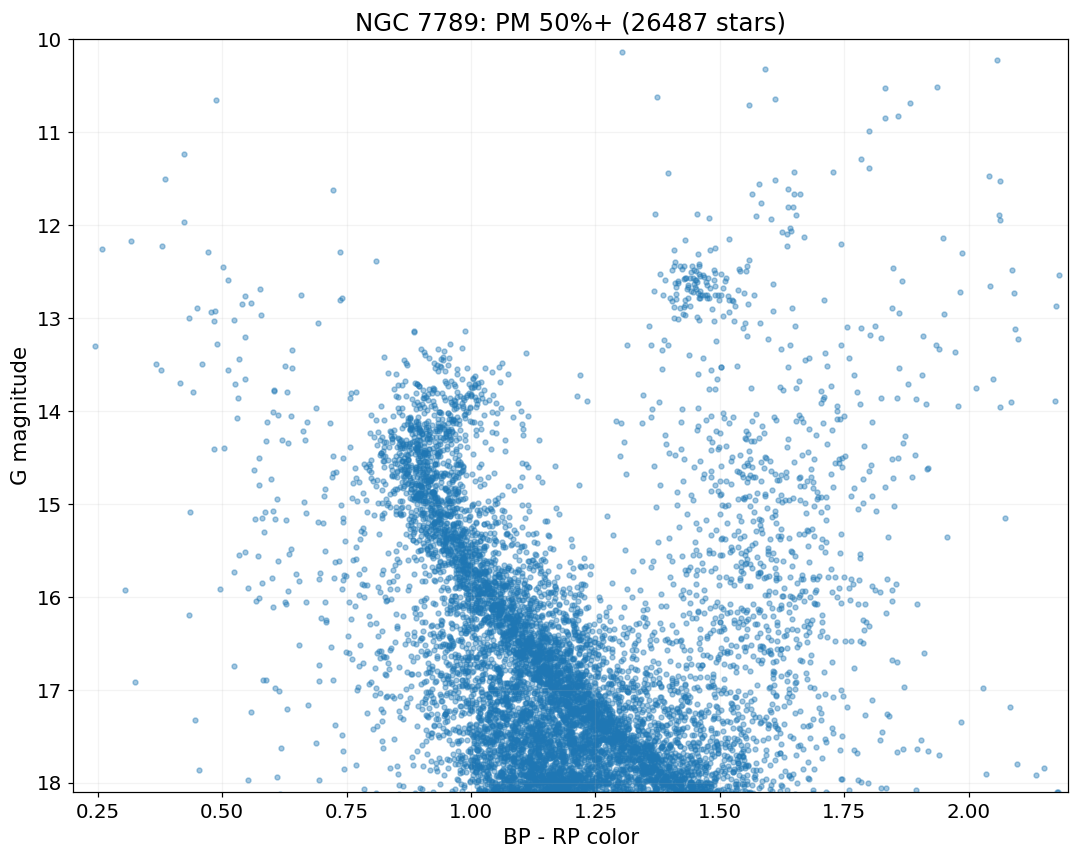

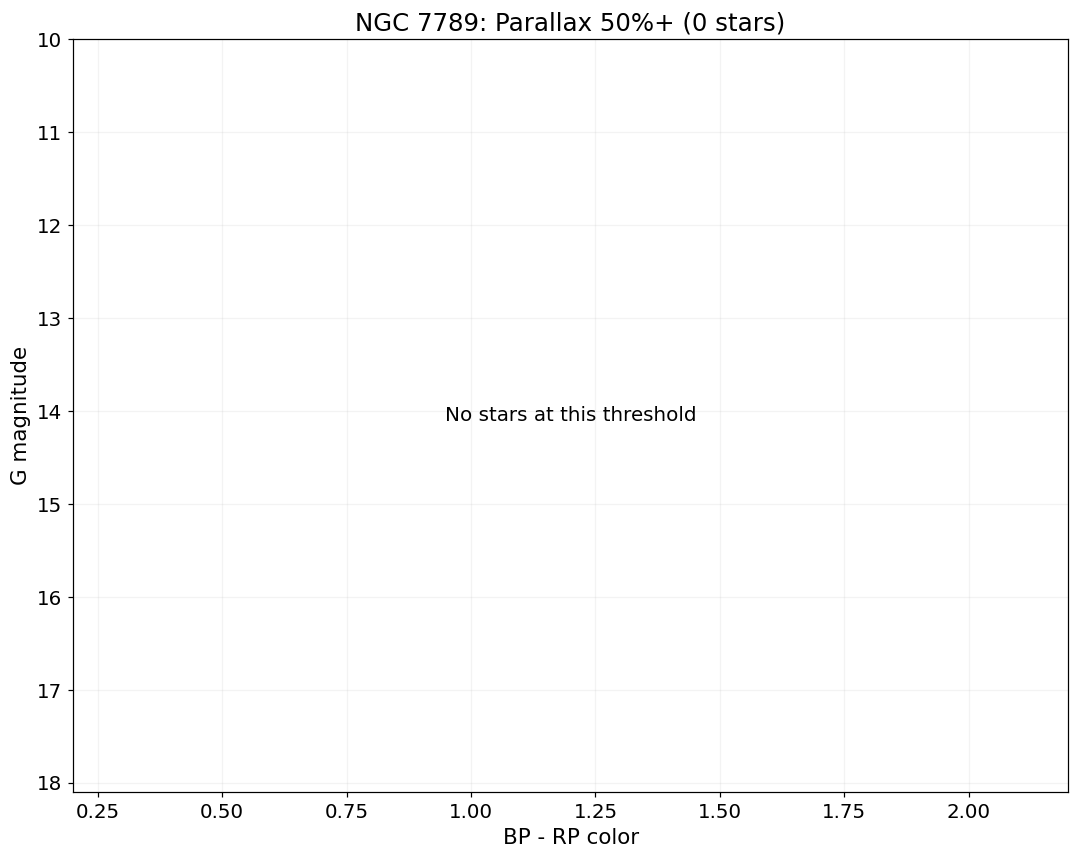

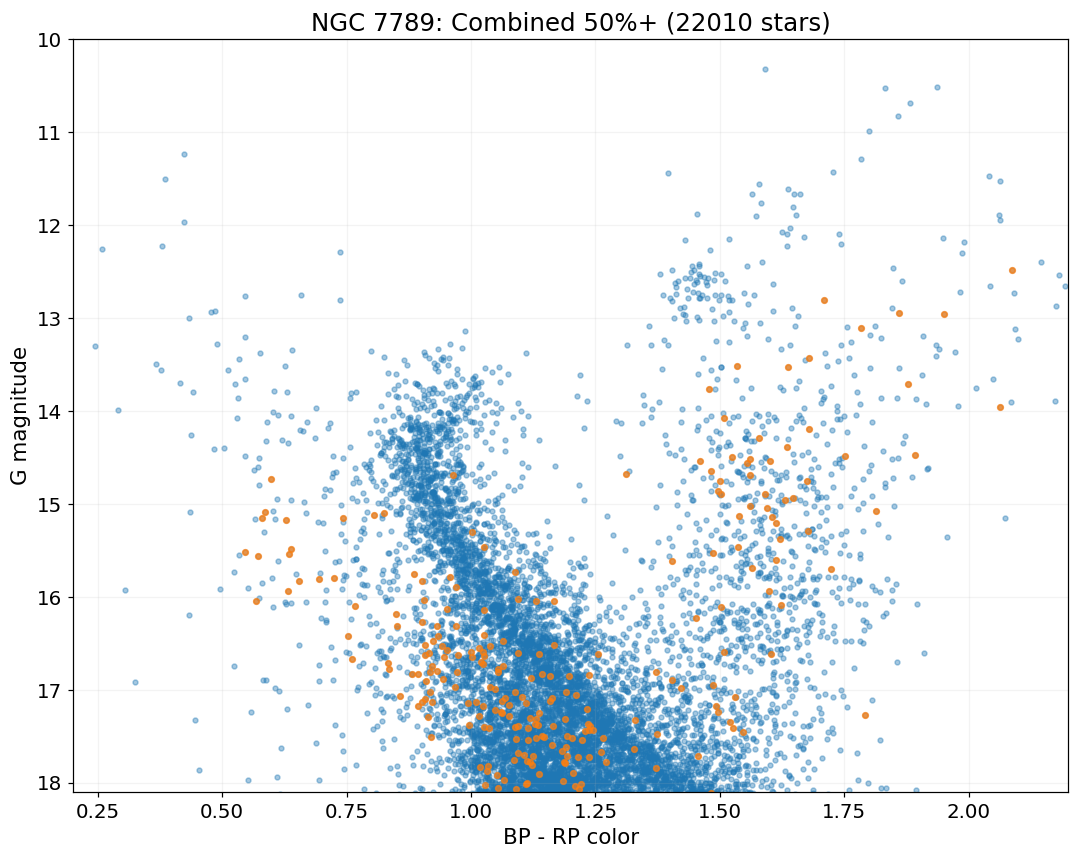

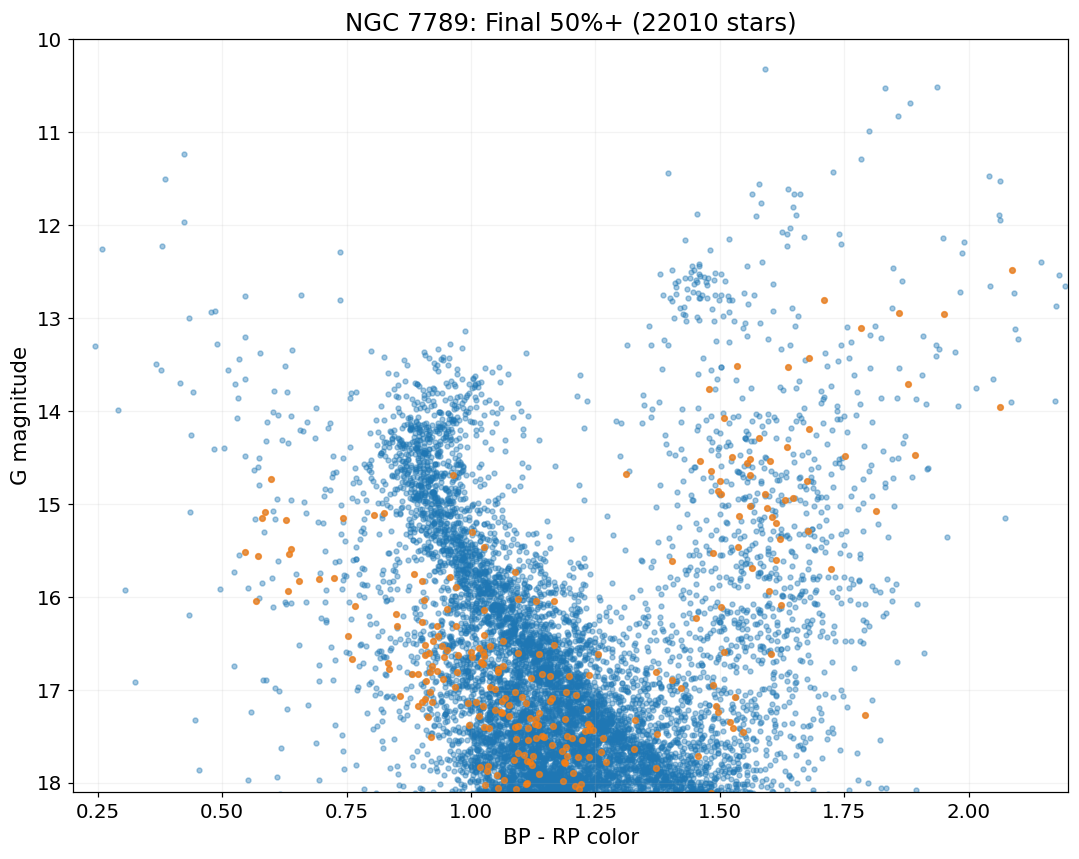

In [3]:
for n,d in data.items():
    for label,col in models.items():
        selected=d.loc[d[col]>=.5]
        core=d.loc[d[col]>=.8]
        fig,ax=plt.subplots(figsize=(10,8))
        ax.scatter(selected.bp_rp,selected.phot_g_mean_mag,s=10,color='tab:blue',alpha=.4,rasterized=True)
        ax.scatter(core.bp_rp,core.phot_g_mean_mag,s=14,color="tab:orange",alpha=.7,rasterized=True)
        ax.set(title=f'NGC {n}: {label} 50%+ ({len(selected)} stars)',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.2),ylim=(18.1,10))
        if selected.empty: ax.text(.5,.5,'No stars at this threshold',ha='center',va='center',transform=ax.transAxes)
        ax.grid(alpha=.15)
        fig.tight_layout(); plt.show()

Where the models agree and disagree

Compare the saved probabilities directly and count overlap at 50%. This shows whether the combined result follows the PM and parallax models. These are model comparisons, not a new membership calculation.

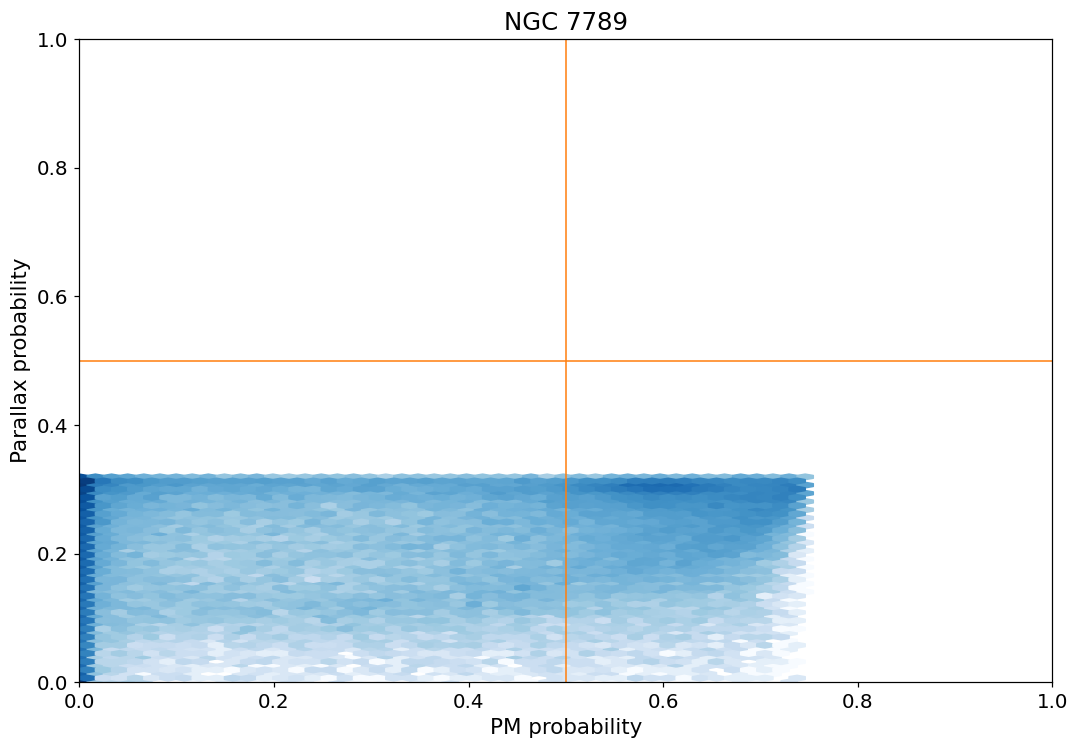

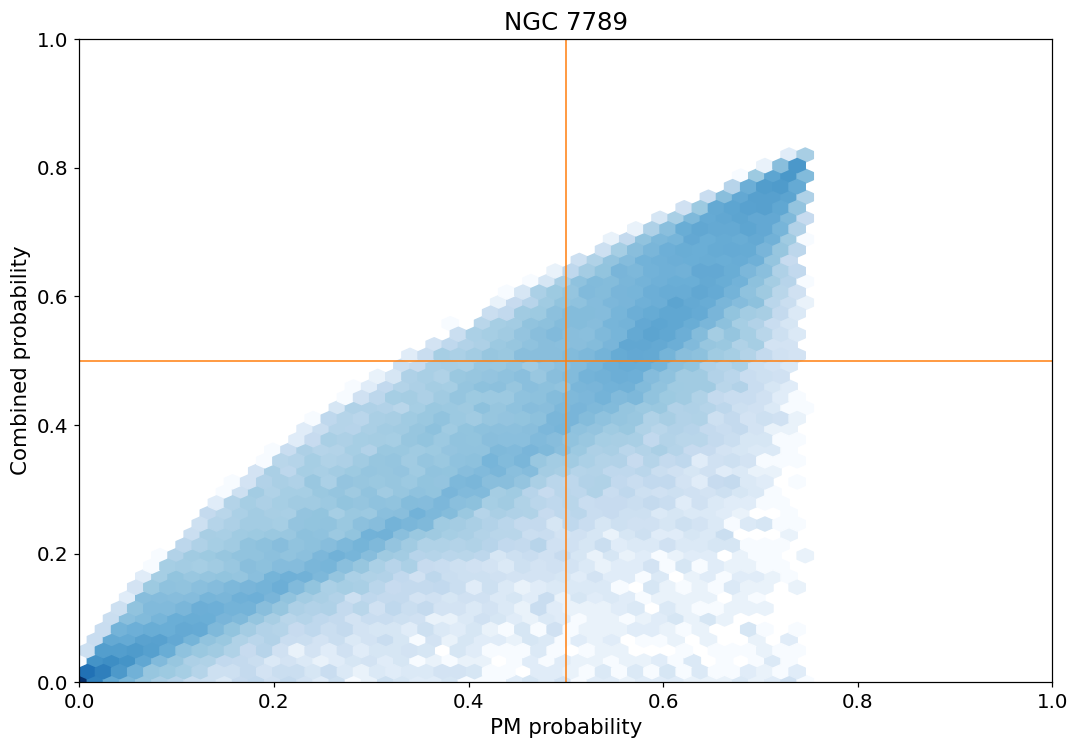

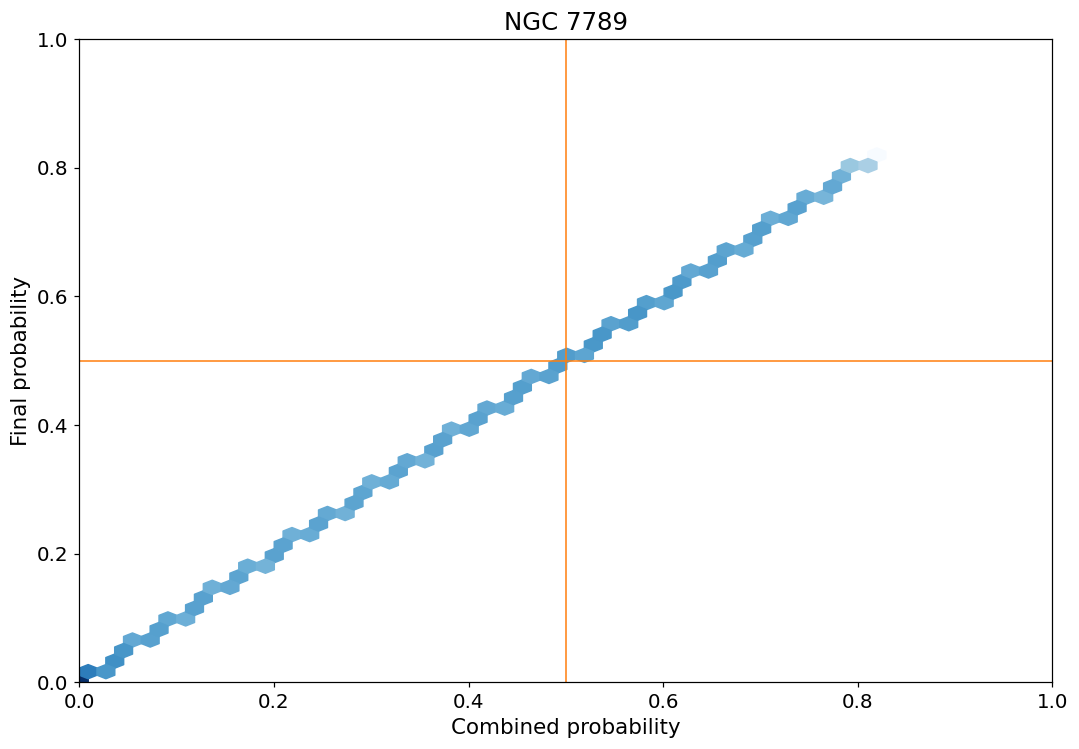

Stars meeting the threshold in both models:


,PM,Parallax,Combined,Final
PM,26487,0,20434,20434
Parallax,0,0,0,0
Combined,20434,0,22010,22010
Final,20434,0,22010,22010


In [4]:
pairs=[('PM','Parallax'),('PM','Combined'),('Combined','Final')]
for n,d in data.items():
    for left,right in pairs:
        fig,ax=plt.subplots(figsize=(10,7))
        ax.hexbin(d[models[left]],d[models[right]],gridsize=45,mincnt=1,bins='log',cmap='Blues')
        ax.axvline(.5,color='tab:orange',linewidth=1); ax.axhline(.5,color='tab:orange',linewidth=1)
        ax.set(title=f'NGC {n}',xlabel=f'{left} probability',ylabel=f'{right} probability',xlim=(0,1),ylim=(0,1))
        fig.tight_layout(); plt.show()
    masks={label:data[n][col]>=.5 for label,col in models.items()}
    overlap=pd.DataFrame({right:{left:int((masks[left]&masks[right]).sum()) for left in models} for right in models})
    print('Stars meeting the threshold in both models:')
    display(overlap)

Inspect blue and red candidates in the saved final sample

Use the final 50%+ stars from the CSV and simple color and magnitude boxes to highlight blue-straggler-like and red-displaced objects. Show the 80%+ subset separately in the counts. Red boxes include possible sub-subgiants and red stragglers, but can also contain ordinary giants or binaries.

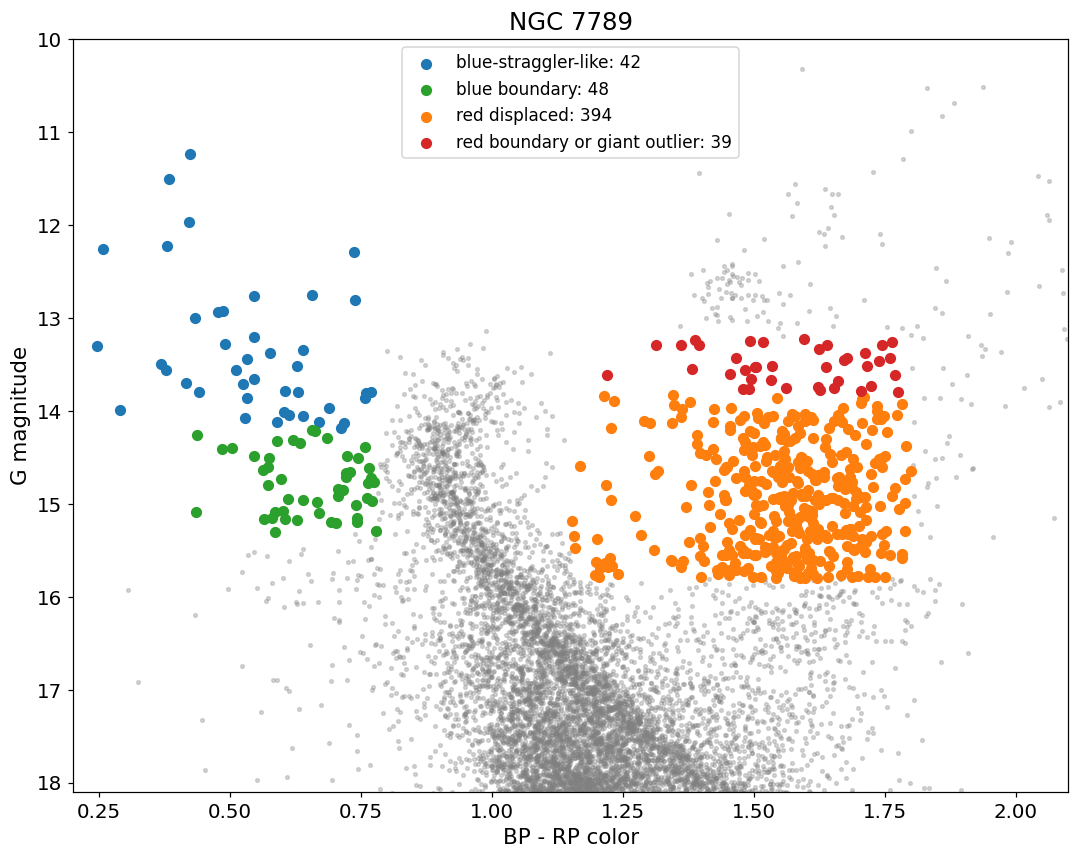

NGC 7789: 523 objects in the inspection boxes


,stars,saved_core
region,,
blue boundary,48,5
blue-straggler-like,42,0
red boundary or giant outlier,39,4
red displaced,394,33


Showing up to 8 objects per region, highest saved probability first. All candidates remain in the candidates dictionary.


,source_id,region,phot_g_mean_mag,bp_rp,radial_velocity,phot_variable_flag,final_member_prob,saved core
0,1995079658387248000,blue boundary,15.086,0.586,NaN,NOT_AVAILABLE,0.816,True
1,1995080826618300032,blue boundary,15.148,0.743,NaN,NOT_AVAILABLE,0.809,True
2,1998085894972110592,blue boundary,15.154,0.579,NaN,NOT_AVAILABLE,0.809,True
3,1995083815915526656,blue boundary,15.172,0.628,NaN,NOT_AVAILABLE,0.808,True
4,1995076394212435072,blue boundary,14.730,0.597,NaN,NOT_AVAILABLE,0.803,True
5,1995019735002059648,blue boundary,15.297,0.585,NaN,NOT_AVAILABLE,0.795,False
6,1998078988663802496,blue boundary,15.165,0.565,NaN,NOT_AVAILABLE,0.792,False
7,1995086599054724608,blue boundary,14.637,0.563,NaN,NOT_AVAILABLE,0.791,False
8,1998102937402247808,blue-straggler-like,14.072,0.529,NaN,NOT_AVAILABLE,0.793,False
9,1995066292449120896,blue-straggler-like,12.808,0.737,NaN,NOT_AVAILABLE,0.789,False


In [5]:
candidates={}
colors={'blue-straggler-like':'tab:blue','blue boundary':'tab:green','red displaced':'tab:orange','red boundary or giant outlier':'tab:red'}
fig,axes=plt.subplots(1,len(samples),figsize=(10*len(samples),8),squeeze=False)
axes=axes.ravel()
for ax,(n,d) in zip(axes,samples.items()):
    g,c=d.phot_g_mean_mag,d.bp_rp
    boxes={'blue-straggler-like':(g<14.2)&c.between(.2,.78,inclusive='neither'),'blue boundary':g.between(14.2,15.3,inclusive='left')&c.between(.2,.78,inclusive='neither'),'red displaced':g.between(13.8,15.8,inclusive='neither')&c.between(1.15,1.8,inclusive='neither'),'red boundary or giant outlier':(g>13.2)&(g<=13.8)&c.between(1.18,1.8,inclusive='neither')}
    ax.scatter(c,g,s=6,color='gray',alpha=.3)
    parts=[]
    for label,mask in boxes.items():
        part=d.loc[mask].copy(); part['region']=label; parts.append(part)
        ax.scatter(part.bp_rp,part.phot_g_mean_mag,s=40,color=colors[label],label=f'{label}: {len(part)}')
    candidates[n]=pd.concat(parts).drop_duplicates('source_id')
    candidates[n]['saved core']=candidates[n].final_member_prob>=.8
    ax.set(title=f'NGC {n}',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.1),ylim=(18.1,10)); ax.legend(fontsize=11)
plt.tight_layout(); plt.show()
columns=['source_id','region','phot_g_mean_mag','bp_rp','radial_velocity','phot_variable_flag','final_member_prob','saved core']
for n,d in candidates.items():
    print(f'NGC {n}: {len(d)} objects in the inspection boxes')
    display(d.groupby('region').agg(stars=('source_id','size'),saved_core=('saved core','sum')))
    shortlist=d.sort_values('final_member_prob',ascending=False).groupby('region',sort=False).head(8)
    print('Showing up to 8 objects per region, highest saved probability first. All candidates remain in the candidates dictionary.')
    display(shortlist[columns].sort_values(['region','final_member_prob'],ascending=[True,False]).round(3).reset_index(drop=True))

Check variability and radial velocities

For the saved final 50%+ sample, compare candidate radial velocities with the sample median. Highlight red candidates and list variable stars. These measurements help identify interesting follow-up objects. In a mixed sample the RV median is only a reference, and binary motion can produce an RV difference.

In [6]:
for n,d in samples.items():
    rv=d.radial_velocity.median()
    print(f'NGC {n}: median radial velocity {rv:.2f} km/s from {d.radial_velocity.notna().sum()} stars')
    picks=candidates[n].copy()
    picks['RV difference']=picks.radial_velocity-rv
    red=picks[picks.region.str.startswith('red')].copy()
    red['variable']=red.phot_variable_flag.eq('VARIABLE')
    red=red.sort_values(['variable','final_member_prob'],ascending=[False,False]).head(15)
    print('Red objects to inspect first:')
    display(red[['source_id','phot_g_mean_mag','bp_rp','phot_variable_flag','radial_velocity','RV difference']].round(3).reset_index(drop=True))
    variables=d[d.phot_variable_flag.eq('VARIABLE')].copy()
    print(f'Other variability leads: {len(variables)} selected variable stars')
    display(variables[['source_id','phot_g_mean_mag','bp_rp','radial_velocity']].sort_values('phot_g_mean_mag').round(3).reset_index(drop=True).head(25))
    print('Showing up to 25 variables, brightest first.')

NGC 7789: median radial velocity -55.64 km/s from 837 stars
Red objects to inspect first:


,source_id,phot_g_mean_mag,bp_rp,phot_variable_flag,radial_velocity,RV difference
0,1995014615400600704,15.709,1.430,VARIABLE,NaN,NaN
1,1994801550662908672,15.552,1.501,VARIABLE,NaN,NaN
2,1995061104128733312,14.061,1.361,VARIABLE,-54.305,1.336
3,1995003276687197824,13.524,1.503,VARIABLE,-66.282,-10.641
4,1994988261480487296,13.520,1.534,NOT_AVAILABLE,-41.474,14.166
5,1995077699882187264,13.427,1.678,NOT_AVAILABLE,-65.890,-10.249
6,421041730004653056,15.201,1.612,NOT_AVAILABLE,NaN,NaN
7,1995037464627914624,14.513,1.560,NOT_AVAILABLE,-86.558,-30.917
8,1995069797142428032,15.374,1.620,NOT_AVAILABLE,NaN,NaN
9,1994997572970644864,14.555,1.555,NOT_AVAILABLE,-92.232,-36.591


Other variability leads: 144 selected variable stars


,source_id,phot_g_mean_mag,bp_rp,radial_velocity
0,1994986784011744640,11.076,3.345,-70.775
1,1995060520013185024,11.218,4.437,-68.376
2,1998080088175767424,12.010,2.792,-36.973
3,1995033513259771776,12.104,3.563,-65.556
4,1995023961249856896,12.211,3.165,-82.327
5,1998059850289734912,12.253,0.258,NaN
6,1994797599293037440,12.530,2.893,-151.026
7,1995010938908719232,12.924,0.486,NaN
8,1995005406991182336,13.277,0.489,NaN
9,1994799626517908096,13.296,0.245,NaN


Showing up to 25 variables, brightest first.


Compare raw and corrected photometry in the saved sample

Plot the same final 50%+ stars before and after correction. Measure the lower-sequence color spread in magnitude bins using identical stars. This describes the saved sample only; it does not reuse the earlier independently selected sample or its 26% result.

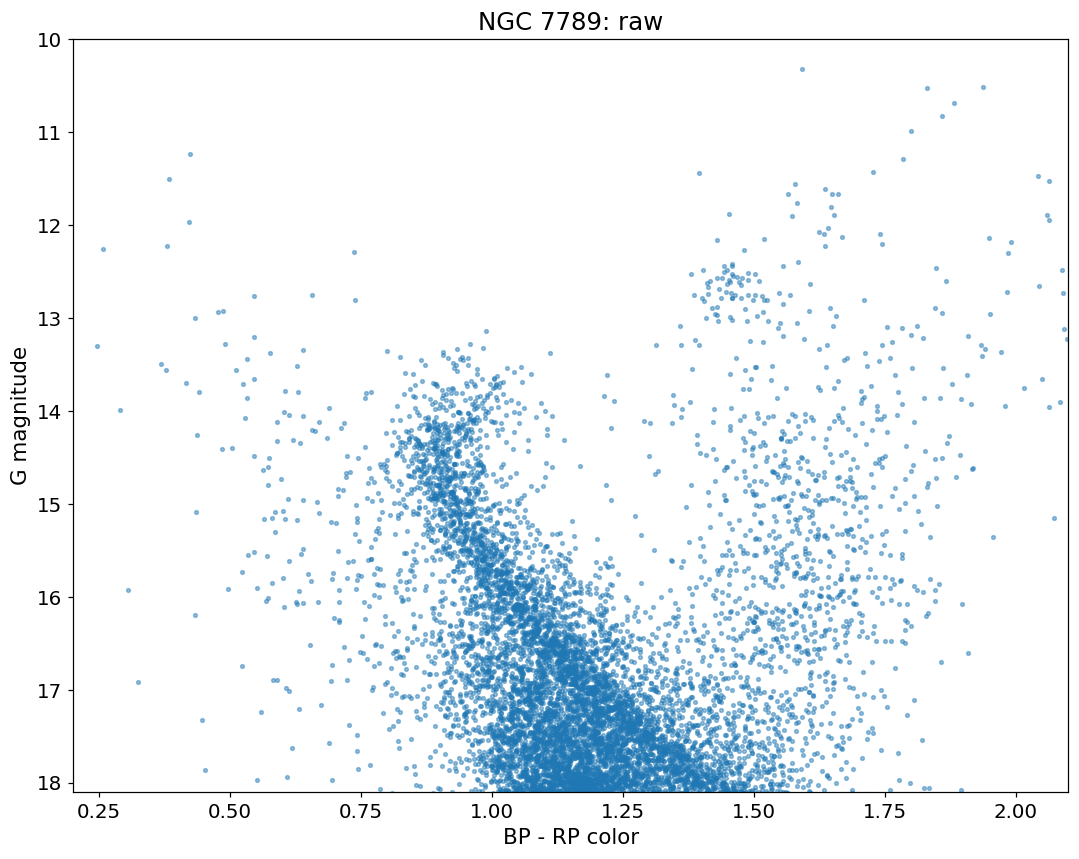

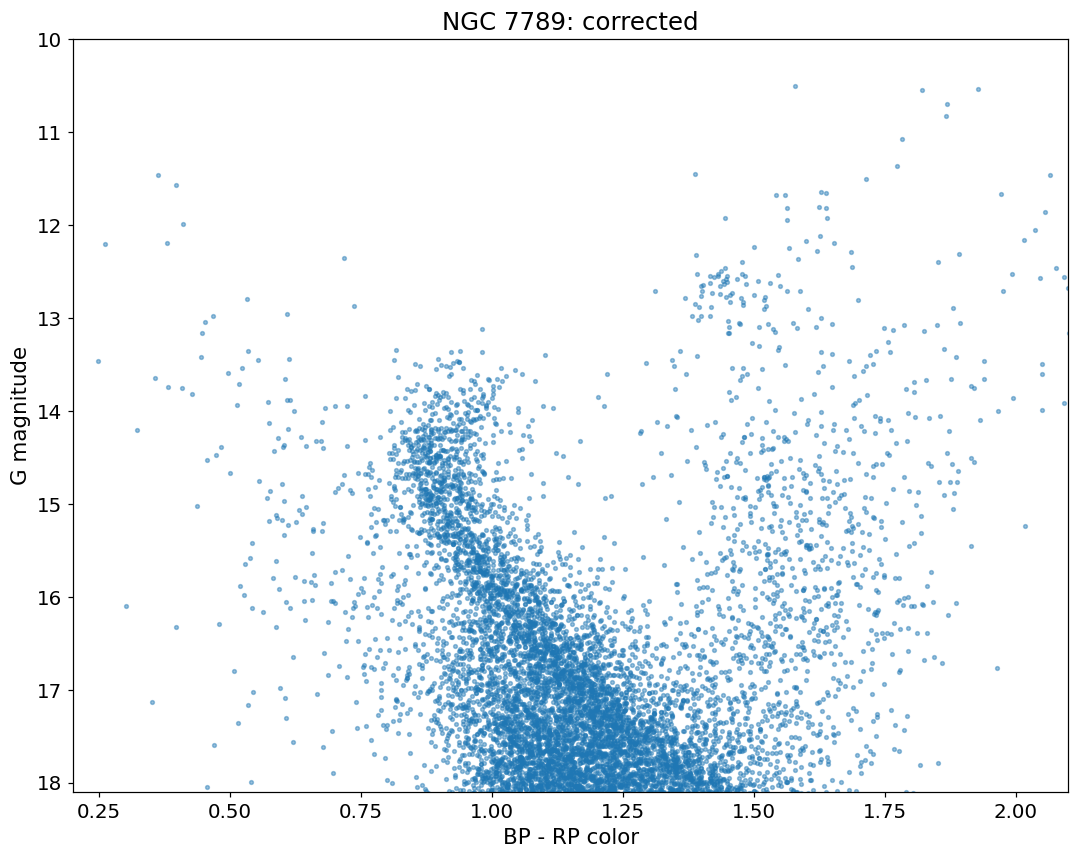

,cluster,same stars,raw color width,corrected color width,width change (%)
0,7789,3770,0.0581,0.0638,9.8225


In [7]:
if not {'bp_rp_corrected','phot_g_mean_mag_corrected'}.issubset(data[7789].columns):
    print('This custom run has no saved corrected photometry to compare.')
else:
    from scipy.stats import gaussian_kde
    def residual(g,c,lo):
        gx,cx=[],[]
        for mid in np.arange(lo,17.9,.25):
            vals=np.asarray(c[(g>=mid-.125)&(g<mid+.125)])
            vals=vals[np.isfinite(vals)&(vals>.2)&(vals<2.8)]
            if len(vals)<8 or np.std(vals)==0: continue
            grid=np.linspace(np.quantile(vals,.05),np.quantile(vals,.95),180)
            density=gaussian_kde(vals,bw_method=max(.1,.035/np.std(vals)))(grid)
            gx.append(mid); cx.append(grid[np.argmax(density)])
        if len(gx)<2: return pd.Series(np.nan,index=c.index)
        return c-np.interp(g,gx,cx,left=np.nan,right=np.nan)
    widths=[]
    for row,(n,d) in enumerate(samples.items()):
        for gcol,ccol,label in zip(['phot_g_mean_mag','phot_g_mean_mag_corrected'],['bp_rp','bp_rp_corrected'],['raw','corrected']):
            fig,ax=plt.subplots(figsize=(10,8))
            ax.scatter(d[ccol],d[gcol],s=6,color='tab:blue',alpha=.45)
            ax.set(title=f'NGC {n}: {label}',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.1),ylim=(18.1,10))
            fig.tight_layout(); plt.show()
        lo=15.3
        r=residual(d.phot_g_mean_mag,d.bp_rp,lo)
        c=residual(d.phot_g_mean_mag_corrected,d.bp_rp_corrected,lo)
        same=(d.phot_g_mean_mag>=lo)&(d.phot_g_mean_mag<17.7)&(r.abs()<.2)&r.notna()&c.notna()
        mad=lambda x: np.median(np.abs(x-np.median(x)))
        rw,cw=mad(r[same]),mad(c[same])
        widths.append({'cluster':n,'same stars':same.sum(),'raw color width':rw,'corrected color width':cw,'width change (%)':100*(cw/rw-1)})
    display(pd.DataFrame(widths).round(4))

Read the custom results

Use the model counts, overlap tables, and diagrams above to see which stars the manually seeded fit assigns high probability. The candidate tables retain those saved probabilities. Compare with the original notebook to see whether the custom fit recovers a clearer sequence.

Core stars: saved probability of 80% or higher

Repeat the plots above with core stars only. Model panels use each model's own saved probability. The candidate and raw/corrected plots use saved final probability of at least 80%.

Select the saved core stars

Use the existing final membership probabilities in the CSVs and count the selected stars. This keeps the earlier 50% section unchanged.

In [8]:
core_samples={n:d.loc[d.final_member_prob>=.8].copy() for n,d in data.items()}
display(pd.DataFrame([{'cluster':n,'final core stars':len(d)} for n,d in core_samples.items()]))

,cluster,final core stars
0,7789,253


Compare the models using core stars

Each panel shows only stars with at least 80% probability in that model. Empty panels mean that model has no core stars.

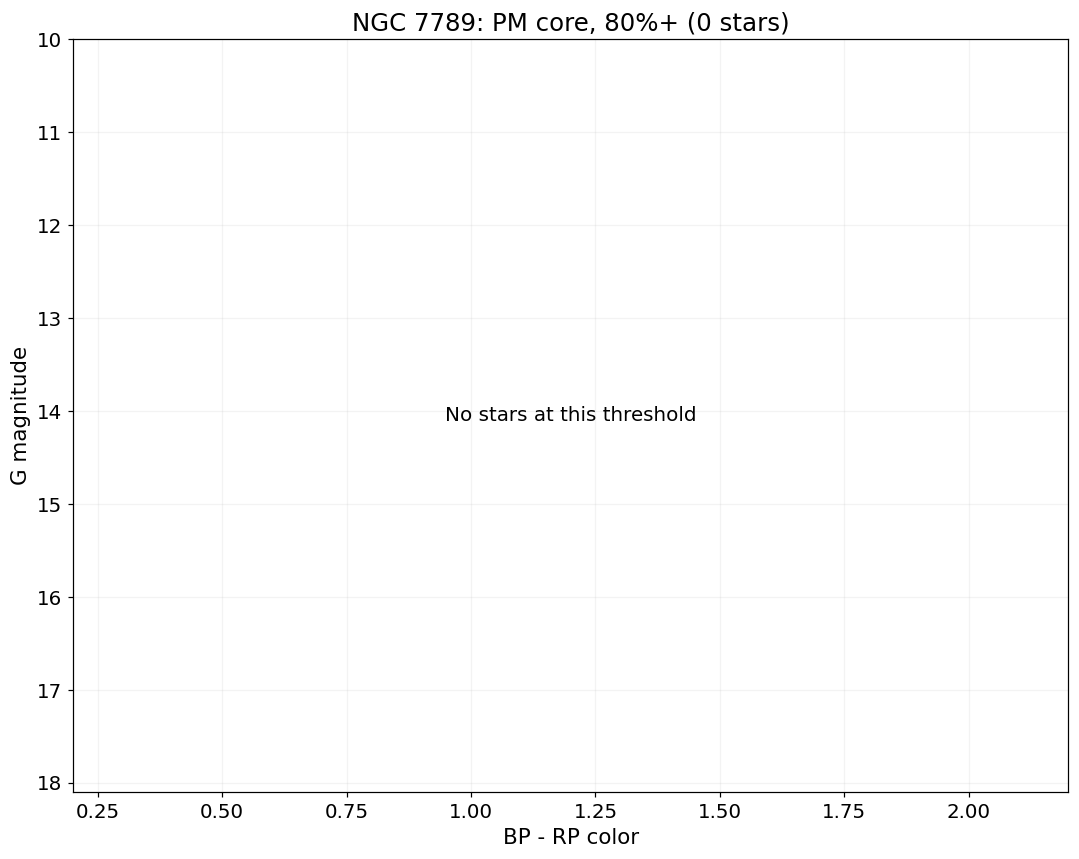

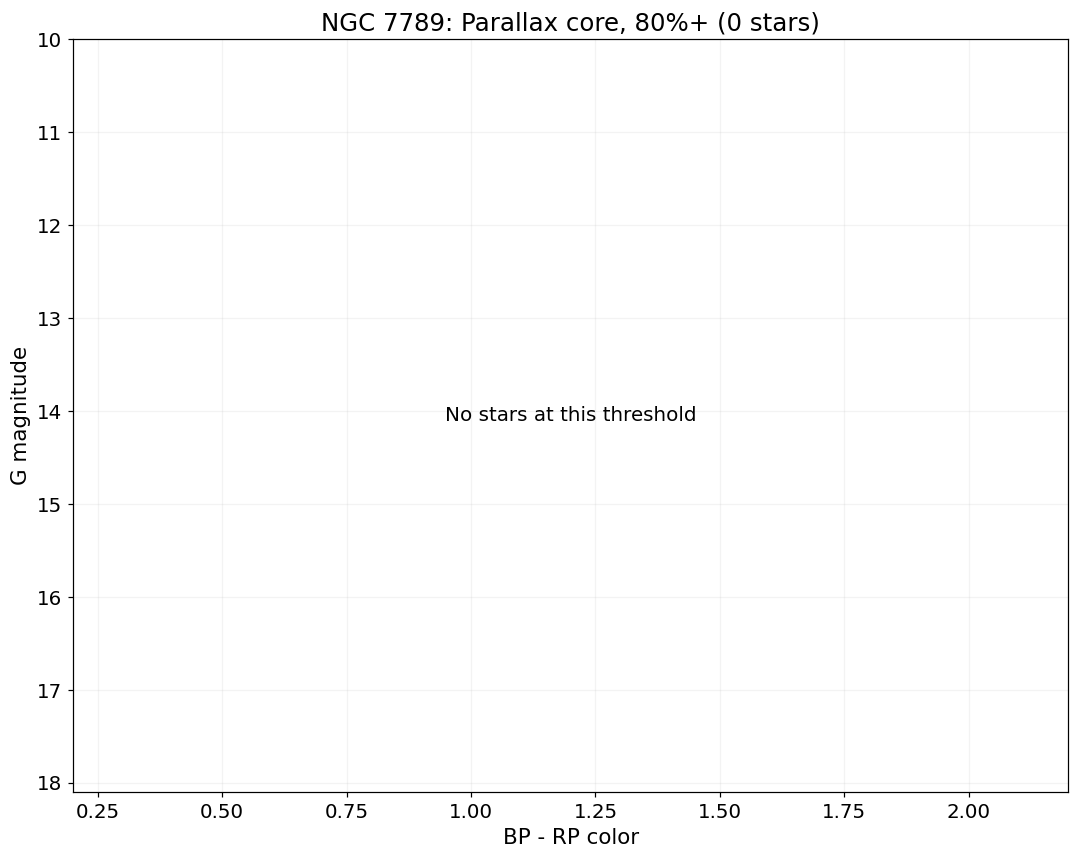

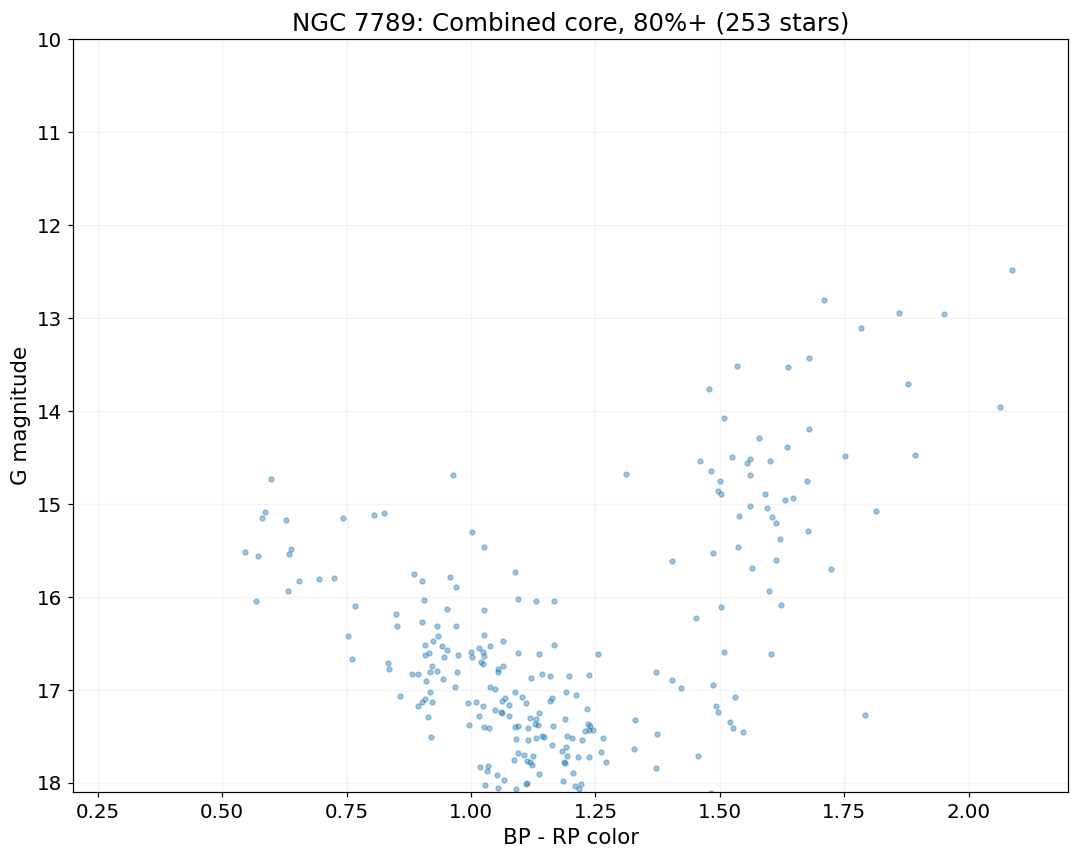

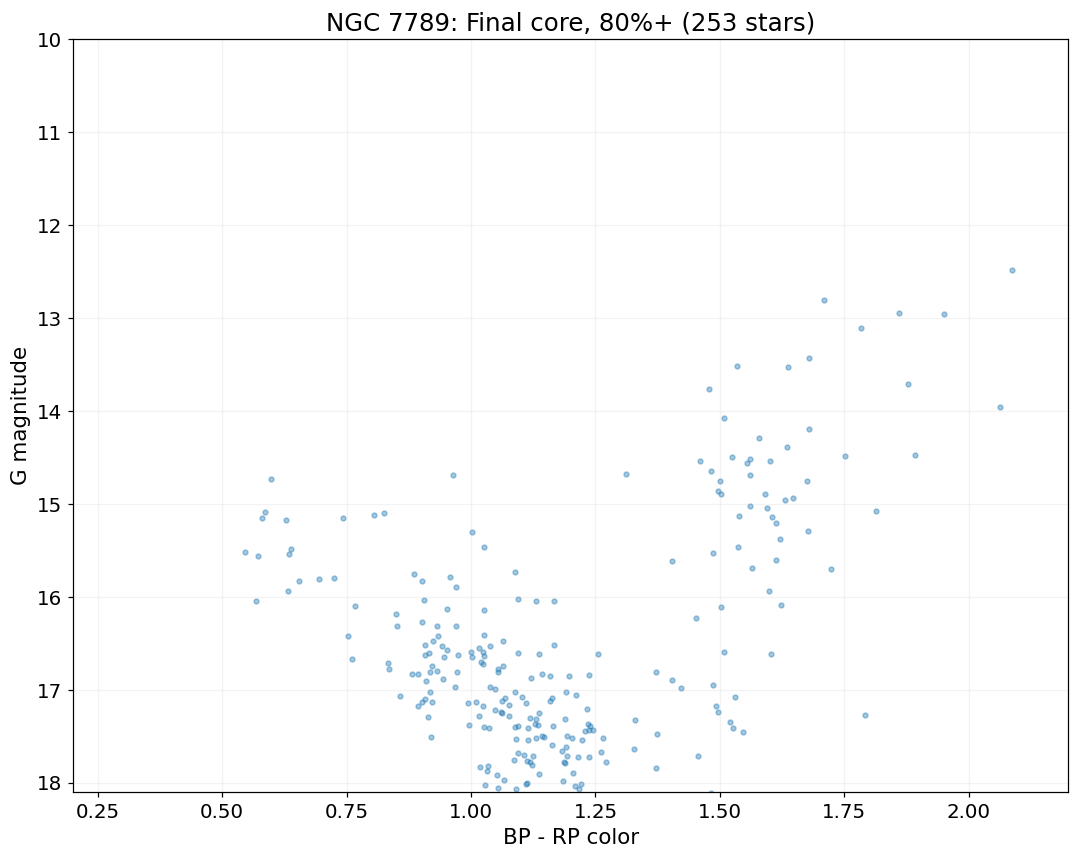

In [9]:
for n,d in data.items():
    for label,col in models.items():
        selected=d.loc[d[col]>=.8]
        core=d.loc[d[col]>=.8]
        fig,ax=plt.subplots(figsize=(10,8))
        ax.scatter(selected.bp_rp,selected.phot_g_mean_mag,s=10,color='tab:blue',alpha=.4,rasterized=True)
        
        ax.set(title=f'NGC {n}: {label} core, 80%+ ({len(selected)} stars)',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.2),ylim=(18.1,10))
        if selected.empty: ax.text(.5,.5,'No stars at this threshold',ha='center',va='center',transform=ax.transAxes)
        ax.grid(alpha=.15)
        fig.tight_layout(); plt.show()

Compare saved probabilities for final core stars

The plots show only final core stars, with 80% reference lines. The overlap tables count stars meeting 80% in both named models across the full CSV.

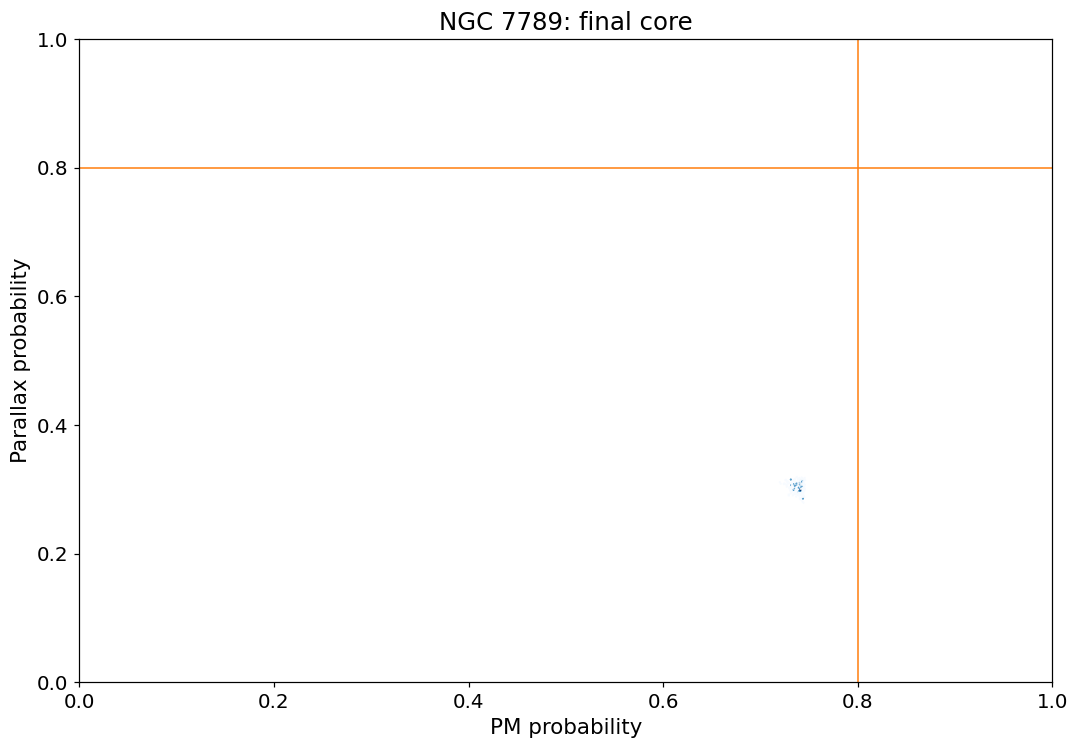

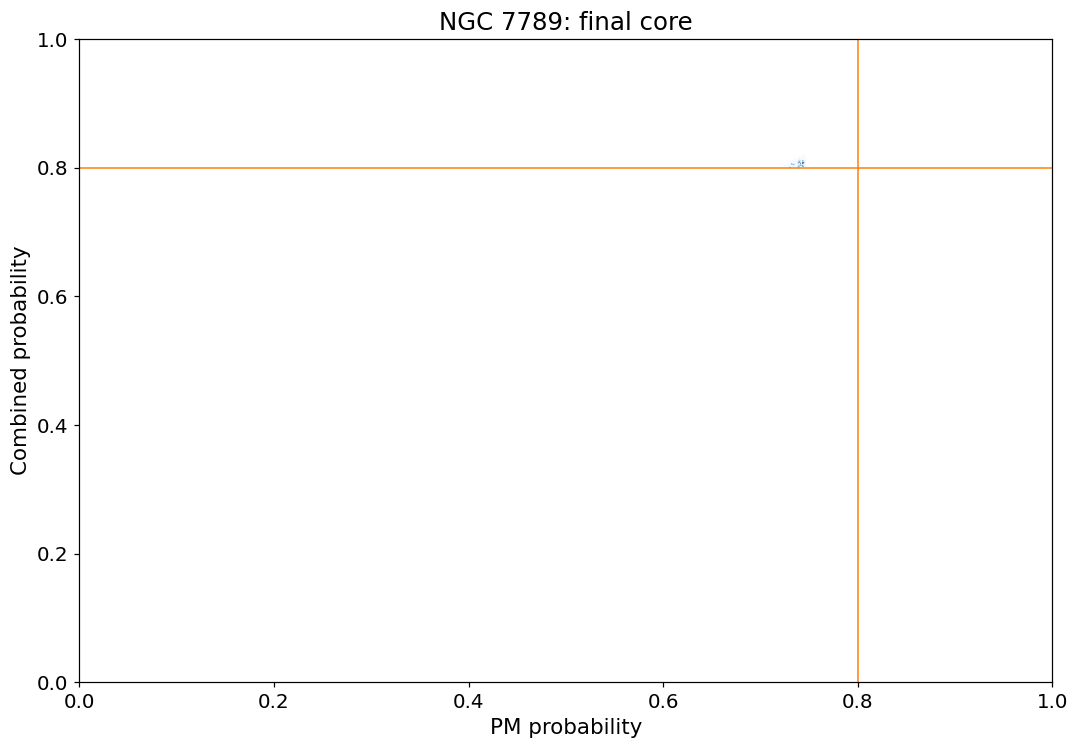

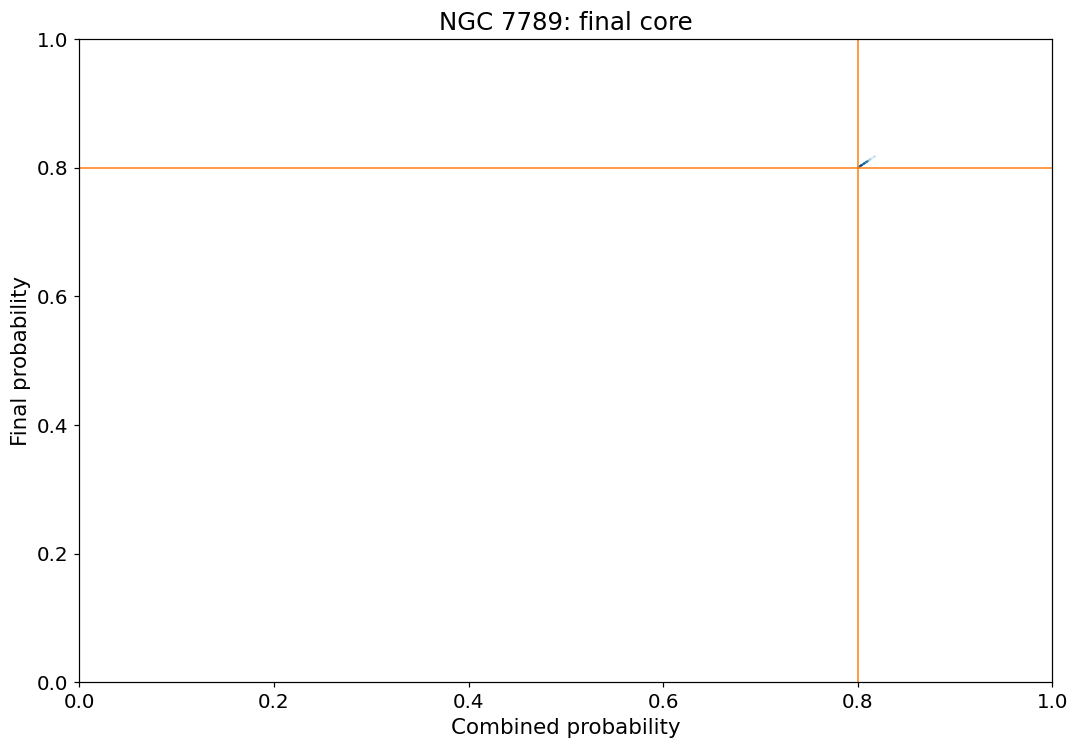

Stars meeting the threshold in both models:


,PM,Parallax,Combined,Final
PM,0,0,0,0
Parallax,0,0,0,0
Combined,0,0,253,253
Final,0,0,253,253


In [10]:
pairs=[('PM','Parallax'),('PM','Combined'),('Combined','Final')]
for n,d in core_samples.items():
    for left,right in pairs:
        fig,ax=plt.subplots(figsize=(10,7))
        ax.hexbin(d[models[left]],d[models[right]],gridsize=45,mincnt=1,bins='log',cmap='Blues')
        ax.axvline(.8,color='tab:orange',linewidth=1); ax.axhline(.8,color='tab:orange',linewidth=1)
        ax.set(title=f'NGC {n}: final core',xlabel=f'{left} probability',ylabel=f'{right} probability',xlim=(0,1),ylim=(0,1))
        fig.tight_layout(); plt.show()
    masks={label:data[n][col]>=.8 for label,col in models.items()}
    overlap=pd.DataFrame({right:{left:int((masks[left]&masks[right]).sum()) for left in models} for right in models})
    print('Stars meeting the threshold in both models:')
    display(overlap)

Inspect blue and red candidates among core stars

Use the same color and magnitude boxes as above, restricted to the saved final core sample. The plots and short tables show which interesting objects remain at 80%.

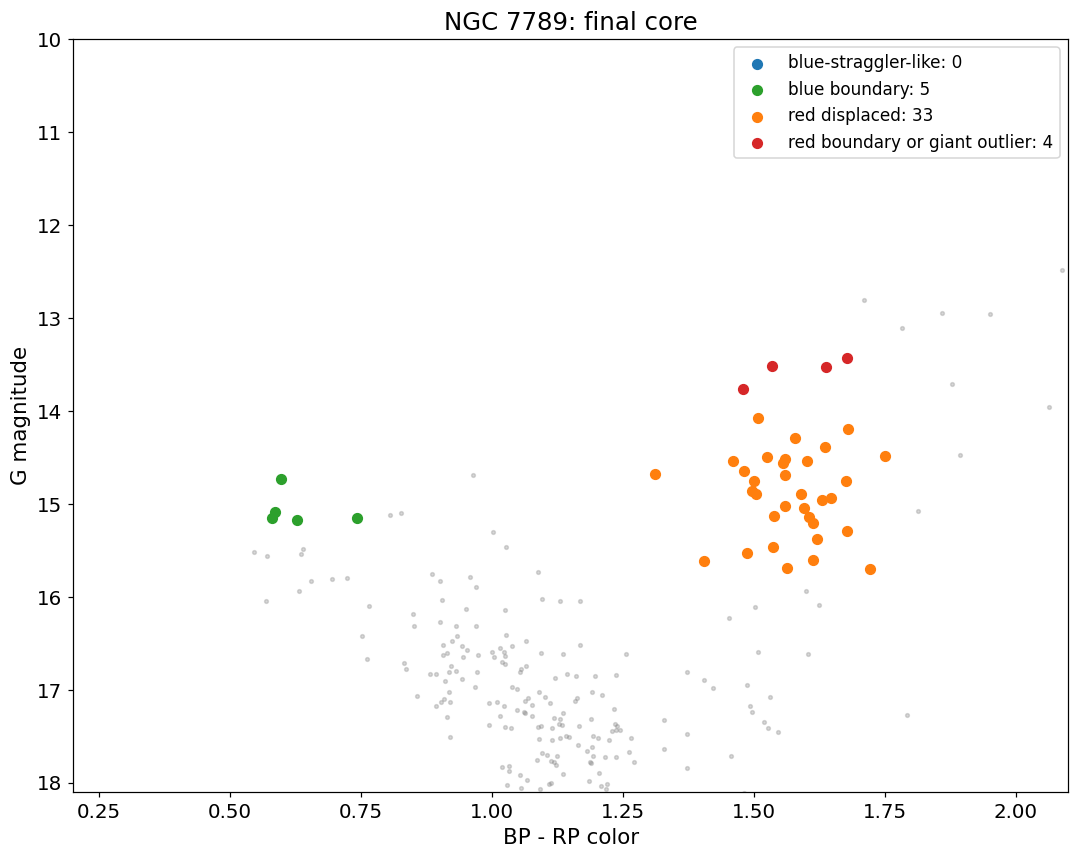

NGC 7789: 42 objects in the inspection boxes


,stars,saved_core
region,,
blue boundary,5,5
red boundary or giant outlier,4,4
red displaced,33,33


Showing up to 8 objects per region, highest saved probability first. All core_candidates remain in the core_candidates dictionary.


,source_id,region,phot_g_mean_mag,bp_rp,radial_velocity,phot_variable_flag,final_member_prob,saved core
0,1995079658387248000,blue boundary,15.086,0.586,NaN,NOT_AVAILABLE,0.816,True
1,1995080826618300032,blue boundary,15.148,0.743,NaN,NOT_AVAILABLE,0.809,True
2,1998085894972110592,blue boundary,15.154,0.579,NaN,NOT_AVAILABLE,0.809,True
3,1995083815915526656,blue boundary,15.172,0.628,NaN,NOT_AVAILABLE,0.808,True
4,1995076394212435072,blue boundary,14.730,0.597,NaN,NOT_AVAILABLE,0.803,True
5,1994988261480487296,red boundary or giant outlier,13.520,1.534,-41.474,NOT_AVAILABLE,0.817,True
6,1995077699882187264,red boundary or giant outlier,13.427,1.678,-65.890,NOT_AVAILABLE,0.816,True
7,1994994205715907840,red boundary or giant outlier,13.761,1.479,-22.747,NOT_AVAILABLE,0.809,True
8,1995063955986667648,red boundary or giant outlier,13.523,1.637,-46.590,NOT_AVAILABLE,0.805,True
9,421041730004653056,red displaced,15.201,1.612,NaN,NOT_AVAILABLE,0.816,True


In [11]:
core_candidates={}
colors={'blue-straggler-like':'tab:blue','blue boundary':'tab:green','red displaced':'tab:orange','red boundary or giant outlier':'tab:red'}
fig,axes=plt.subplots(1,len(core_samples),figsize=(10*len(core_samples),8),squeeze=False)
axes=axes.ravel()
for ax,(n,d) in zip(axes,core_samples.items()):
    g,c=d.phot_g_mean_mag,d.bp_rp
    boxes={'blue-straggler-like':(g<14.2)&c.between(.2,.78,inclusive='neither'),'blue boundary':g.between(14.2,15.3,inclusive='left')&c.between(.2,.78,inclusive='neither'),'red displaced':g.between(13.8,15.8,inclusive='neither')&c.between(1.15,1.8,inclusive='neither'),'red boundary or giant outlier':(g>13.2)&(g<=13.8)&c.between(1.18,1.8,inclusive='neither')}
    ax.scatter(c,g,s=6,color='gray',alpha=.3)
    parts=[]
    for label,mask in boxes.items():
        part=d.loc[mask].copy(); part['region']=label; parts.append(part)
        ax.scatter(part.bp_rp,part.phot_g_mean_mag,s=40,color=colors[label],label=f'{label}: {len(part)}')
    core_candidates[n]=pd.concat(parts).drop_duplicates('source_id')
    core_candidates[n]['saved core']=core_candidates[n].final_member_prob>=.8
    ax.set(title=f'NGC {n}: final core',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.1),ylim=(18.1,10)); ax.legend(fontsize=11)
plt.tight_layout(); plt.show()
columns=['source_id','region','phot_g_mean_mag','bp_rp','radial_velocity','phot_variable_flag','final_member_prob','saved core']
for n,d in core_candidates.items():
    print(f'NGC {n}: {len(d)} objects in the inspection boxes')
    display(d.groupby('region').agg(stars=('source_id','size'),saved_core=('saved core','sum')))
    shortlist=d.sort_values('final_member_prob',ascending=False).groupby('region',sort=False).head(8)
    print('Showing up to 8 objects per region, highest saved probability first. All core_candidates remain in the core_candidates dictionary.')
    display(shortlist[columns].sort_values(['region','final_member_prob'],ascending=[True,False]).round(3).reset_index(drop=True))

Compare raw and corrected core diagrams

Plot the same final core stars before and after correction. The width calculation uses the same method and magnitude ranges as above. Missing widths mean too few suitable stars to measure the sequence.

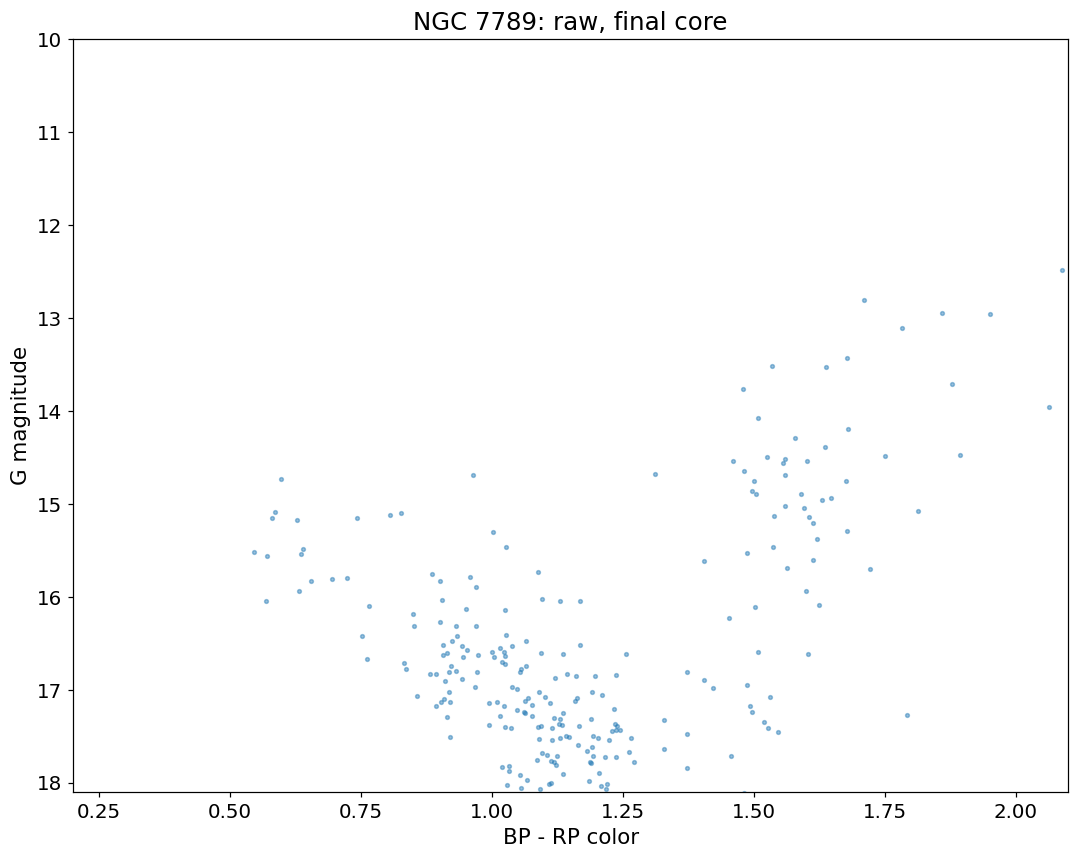

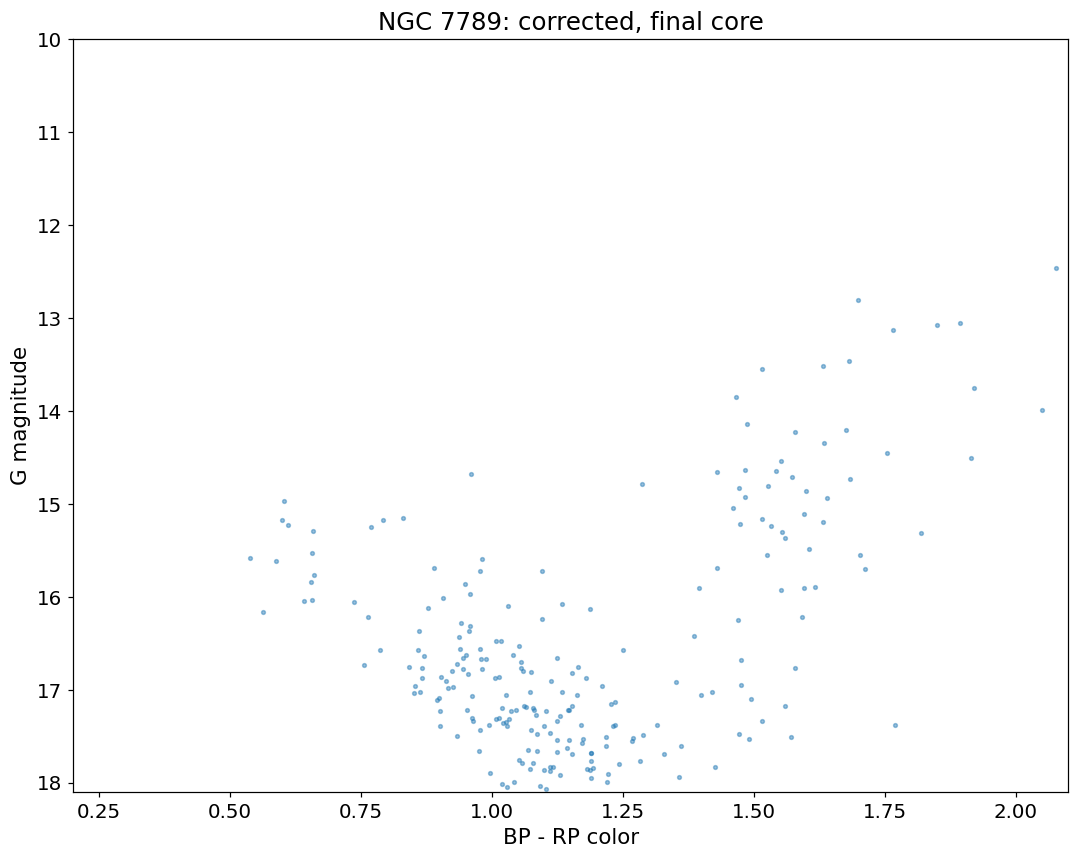

,cluster,same stars,raw color width,corrected color width,width change (%)
0,7789,114,0.0537,0.0724,34.6893


In [12]:
if not {'bp_rp_corrected','phot_g_mean_mag_corrected'}.issubset(data[7789].columns):
    print('This custom run has no saved corrected photometry to compare.')
else:
    core_widths=[]
    for row,(n,d) in enumerate(core_samples.items()):
        for gcol,ccol,label in zip(['phot_g_mean_mag','phot_g_mean_mag_corrected'],['bp_rp','bp_rp_corrected'],['raw','corrected']):
            fig,ax=plt.subplots(figsize=(10,8))
            ax.scatter(d[ccol],d[gcol],s=6,color='tab:blue',alpha=.45)
            ax.set(title=f'NGC {n}: {label}, final core',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.1),ylim=(18.1,10))
            fig.tight_layout(); plt.show()
        lo=15.3
        r=residual(d.phot_g_mean_mag,d.bp_rp,lo)
        c=residual(d.phot_g_mean_mag_corrected,d.bp_rp_corrected,lo)
        same=(d.phot_g_mean_mag>=lo)&(d.phot_g_mean_mag<17.7)&(r.abs()<.2)&r.notna()&c.notna()
        mad=lambda x: np.median(np.abs(x-np.median(x)))
        rw,cw=(mad(r[same]),mad(c[same])) if same.any() else (np.nan,np.nan)
        core_widths.append({'cluster':n,'same stars':same.sum(),'raw color width':rw,'corrected color width':cw,'width change (%)':100*(cw/rw-1) if np.isfinite(rw) and rw>0 else np.nan})
    display(pd.DataFrame(core_widths).round(4))

Compare the four starting seeds

Test the original median, quadrature, and density starts against the manual CMD start. We keep the full star list, field model, spatial weight, fitting rules, and saved PM/parallax support the same for all four combined-model fits. This isolates what changing the combined-model initialization does. The original and custom scripts are only imported, not edited or run as programs.

Prepare the seed comparison

Load the fitting functions and the same stars used by the custom run. The calculation below evaluates the same Gaussian likelihood in batches to make four full fits practical. A small numerical check compares it with the original calculation before using it.

In [13]:
import importlib.util
import ast
from scipy.special import expit
from contextlib import redirect_stdout
import io

def load_analysis_module(name,filename):
    spec=importlib.util.spec_from_file_location(name,ROOT/filename)
    module=importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

auto_model=load_analysis_module('automatic_analysis','cluster_analysis.py')
manual_model=load_analysis_module('manual_analysis','7789_custom_analysis.py')
seed_df=data[7789].copy().reset_index(drop=True)
assert seed_df.source_id.is_unique
pm=seed_df[['pmra','pmdec']].to_numpy(float)
parallax=seed_df.parallax.to_numpy(float)
xsky,ysky,ra0,dec0=auto_model.add_projected_xy(seed_df)
raw5=np.column_stack([pm,parallax,xsky,ysky])
normalized,means,stds=auto_model.normalize_data_5d(raw5)
astro_support=seed_df.pm_only_prob.to_numpy(float).copy()
astro_support[seed_df.plx_only_prob.to_numpy(float)<.2]*=.5
spatial_weight=auto_model.adaptive_spatial_weight(xsky,ysky,astro_support)
normalized[:,3:]*=spatial_weight
errors5=np.column_stack([seed_df.pmra_error,seed_df.pmdec_error,seed_df.parallax_error,
                         np.full(len(seed_df),auto_model.SPATIAL_ERROR_FLOOR_DEG),
                         np.full(len(seed_df),auto_model.SPATIAL_ERROR_FLOOR_DEG)])/stds
errors5[:,3:]*=spatial_weight
field_center,field_cov=auto_model.fixed_field_component_5d_normalized(normalized)
max_pi=auto_model.estimate_adaptive_max_pi(pm)
raw_scale=stds.copy(); raw_scale[3:]/=spatial_weight

def batch_gaussian(values,center,cov,errors=None):
    n,dim=values.shape
    base=np.asarray(cov)+auto_model.COV_REG*np.eye(dim)
    answer=np.empty(n)
    for start in range(0,n,8192):
        stop=min(start+8192,n)
        matrix=np.broadcast_to(base,(stop-start,dim,dim)).copy()
        if errors is not None:
            matrix[:,np.arange(dim),np.arange(dim)]+=errors[start:stop]**2
        chol=np.linalg.cholesky(matrix)
        solved=np.linalg.solve(chol,(values[start:stop]-center)[...,None])[...,0]
        logdet=2*np.log(np.diagonal(chol,axis1=1,axis2=2)).sum(axis=1)
        answer[start:stop]=-.5*(dim*np.log(2*np.pi)+logdet+(solved**2).sum(axis=1))
    return answer

reference=auto_model.mvnpdf_log_nd(normalized[:32],np.zeros(5),np.eye(5),errors5[:32])
np.testing.assert_allclose(batch_gaussian(normalized[:32],np.zeros(5),np.eye(5),errors5[:32]),reference,rtol=1e-12,atol=1e-12)
print(f'{len(seed_df):,} stars in every fit; same max cluster fraction {max_pi:.3f} and spatial weight {spatial_weight:.3f}.')

  Spatial weight debug: concentration=1.771, c_low=nan, c_high=nan, weight=0.317
73,625 stars in every fit; same max cluster fraction 0.080 and spatial weight 0.317.


Define the starts and count their initial stars

The three automatic seeds are starting centers and widths, not drawn groups of stars. For a common comparison, count stars with at least 50% or 80% membership probability before the first update. Also show the actual drawn count for the manual seed. The manual polygon is recovered from the saved run, rather than assuming the current script still uses the same drawing.

In [14]:
print('Calculating the original automatic seed locations...',flush=True)
automatic_centers=auto_model.generate_joint_seeds(pm,parallax)
xseed,yseed=auto_model.generate_spatially_aware_seed(xsky,ysky)
starts={}
for name,center3 in automatic_centers:
    center_raw=np.r_[center3,xseed,yseed]
    center=(center_raw-means)/stds; center[3:]*=spatial_weight
    spm=auto_model.estimate_sigma_from_core(pm,center3[:2])
    splx=max(.05,.6*np.std(parallax))
    ssky=auto_model.estimate_sigma_spatial_core(xsky,ysky)
    scale=np.array([spm,spm,splx,ssky,ssky])/stds; scale[3:]*=spatial_weight
    starts[name]={'center':center,'cov':np.diag(scale**2),'pi':.1}
quality_path=RESULTS.with_name('NGC7789_custom-result_quality_summary.csv')
quality=pd.read_csv(quality_path).iloc[0]
vertices=np.array(ast.literal_eval(quality.manual_seed_vertices),dtype=float)
manual_mask=manual_model.manual_cmd_seed_mask(seed_df,vertices)
if 'manual_cmd_seed' in seed_df:
    np.testing.assert_array_equal(manual_mask,seed_df.manual_cmd_seed.to_numpy(bool))
center,scale=manual_model.seed_location_scale(normalized[manual_mask])
starts['manual']={'center':center,'cov':np.diag(scale**2),'pi':float(np.clip(manual_mask.mean(),auto_model.MIN_PI,max_pi))}
field_logpdf=batch_gaussian(normalized,field_center,field_cov,errors5)
initial_rows=[]
for name,start in starts.items():
    lc=batch_gaussian(normalized,start['center'],start['cov'],errors5)
    p=expit(np.log(start['pi'])+lc-np.log1p(-start['pi'])-field_logpdf)
    start['prob']=p
    loc=start['center']*raw_scale+means
    initial_rows.append({'seed':name,'drawn stars':int(manual_mask.sum()) if name=='manual' else pd.NA,
                         'initial P >= 0.5':int((p>=.5).sum()),'initial P >= 0.8':int((p>=.8).sum()),
                         'initial PM RA':loc[0],'initial PM Dec':loc[1],'initial parallax':loc[2],
                         'initial sky X (arcmin)':60*loc[3],'initial sky Y (arcmin)':60*loc[4],
                         'initial cluster fraction':start['pi']})
initial_summary=pd.DataFrame(initial_rows).set_index('seed')
display(initial_summary.round(4))

Calculating the original automatic seed locations...


,drawn stars,initial P >= 0.5,initial P >= 0.8,initial PM RA,initial PM Dec,initial parallax,initial sky X (arcmin),initial sky Y (arcmin),initial cluster fraction
seed,,,,,,,,,
median,<NA>,18142,903,-1.6070,-1.2121,0.3470,0.2683,0.3941,0.10
quadrature,<NA>,14195,834,-2.0898,-0.6788,0.3470,0.2683,0.3941,0.10
density,<NA>,18546,943,-1.6828,-1.1570,0.2830,0.2683,0.3941,0.10
manual,20190,14569,0,-1.5864,-1.4922,0.3603,-0.4615,-0.8231,0.08


Fit all four starts and compare their final core counts

Run the existing combined-model fitter once per seed on all stars. Keep the saved PM/parallax support fixed and apply the pipeline's usual final probability gate. Record how the center moves at each update and count both combined and final core stars. No seed is discarded in favor of another.

In [16]:
seed_results={}
original_pdf=auto_model.mvnpdf_log_nd
for name,start in starts.items():
    print(f'Fitting {name}...',flush=True)
    trace=[];call_count=[0]
    def tracked_pdf(values,center,cov,errors=None):
        is_cluster=call_count[0]%2==0
        call_count[0]+=1
        if is_cluster:
            trace.append(np.array(center,copy=True))
            return batch_gaussian(values,center,cov,errors)
        return field_logpdf
    try:
        auto_model.mvnpdf_log_nd=tracked_pdf
        center,cov,combined,pi=auto_model.fit_cluster_nd(
            normalized,start['center'].copy(),start['cov'].copy(),field_center,field_cov,errors5,
            pi_cluster=start['pi'],min_pi=auto_model.MIN_PI,max_pi=max_pi)
    finally:
        auto_model.mvnpdf_log_nd=original_pdf
    final=combined.copy()
    gate=(combined>=.8)&(astro_support<.5)
    final[gate]=np.minimum(final[gate],astro_support[gate])
    ll=np.logaddexp(np.log(pi)+batch_gaussian(normalized,center,cov,errors5),np.log1p(-pi)+field_logpdf).sum()
    seed_results[name]={'center':center*raw_scale+means,'cov':cov*np.outer(raw_scale,raw_scale),
                        'combined':combined,'final':final,'core':final>=.8,'pi':pi,'log likelihood':ll,
                        'trace':np.array(trace)*raw_scale+means,'iterations':len(trace)-1,
                        'last center change':np.linalg.norm(trace[-1]-trace[-2])}
    print(f'{name}: {(final>=.8).sum():,} final core stars after {len(trace)-1} updates',flush=True)
final_rows=[]
for name,result in seed_results.items():
    c=result['center']
    final_rows.append({'seed':name,'updates':result['iterations'],'center tolerance reached':result['last center change']<1e-4,
                       'combined core stars':int((result['combined']>=.8).sum()),'final core stars':int(result['core'].sum()),
                       'final P >= 0.5':int((result['final']>=.5).sum()),'final PM RA':c[0],'final PM Dec':c[1],
                       'final parallax':c[2],'cluster fraction':result['pi'],'log likelihood':result['log likelihood']})
final_summary=pd.DataFrame(final_rows).set_index('seed')
display(final_summary.round(5))
print('Max absolute final-probability difference from the saved custom run:')
print(float(np.max(np.abs(seed_results['manual']['final']-seed_df.final_member_prob.to_numpy()))))

Fitting median...


median: 253 final core stars after 12 updates


Fitting quadrature...


quadrature: 253 final core stars after 12 updates


Fitting density...


density: 253 final core stars after 11 updates


Fitting manual...


manual: 253 final core stars after 12 updates


,updates,center tolerance reached,combined core stars,final core stars,final P >= 0.5,final PM RA,final PM Dec,final parallax,cluster fraction,log likelihood
seed,,,,,,,,,,
median,12,True,253,253,22016,-1.61692,-1.10540,0.24368,0.08,-317885.41309
quadrature,12,True,253,253,22010,-1.61774,-1.10508,0.24365,0.08,-317887.29416
density,11,True,253,253,22017,-1.61690,-1.10543,0.24369,0.08,-317885.34276
manual,12,True,253,253,22010,-1.61761,-1.10532,0.24368,0.08,-317886.92604


Max absolute final-probability difference from the saved custom run:
9.43689570931383e-16


Show the starting star locations

Use the same initial 50% probability threshold for all four starts and overlay their stars in the CMD, proper-motion plane, and sky. The red outline on the CMD is the drawn manual sample; its points and the manual model's initial probabilities are different quantities.

Directly below the initial proper-motion plot, overlay the final 80%+ core stars from each seed on the same axes. The initial plot uses 50%+ probabilities; the final plot uses the core threshold. Colored rings show the overlapping groups.

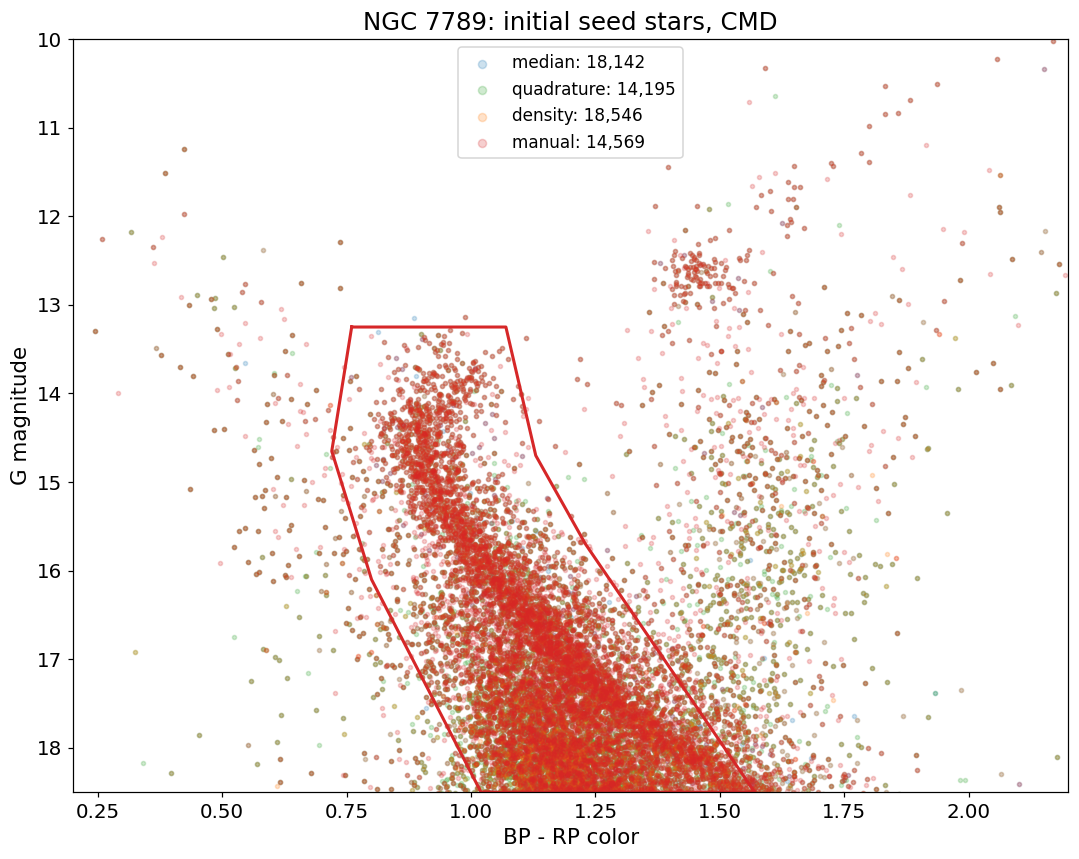

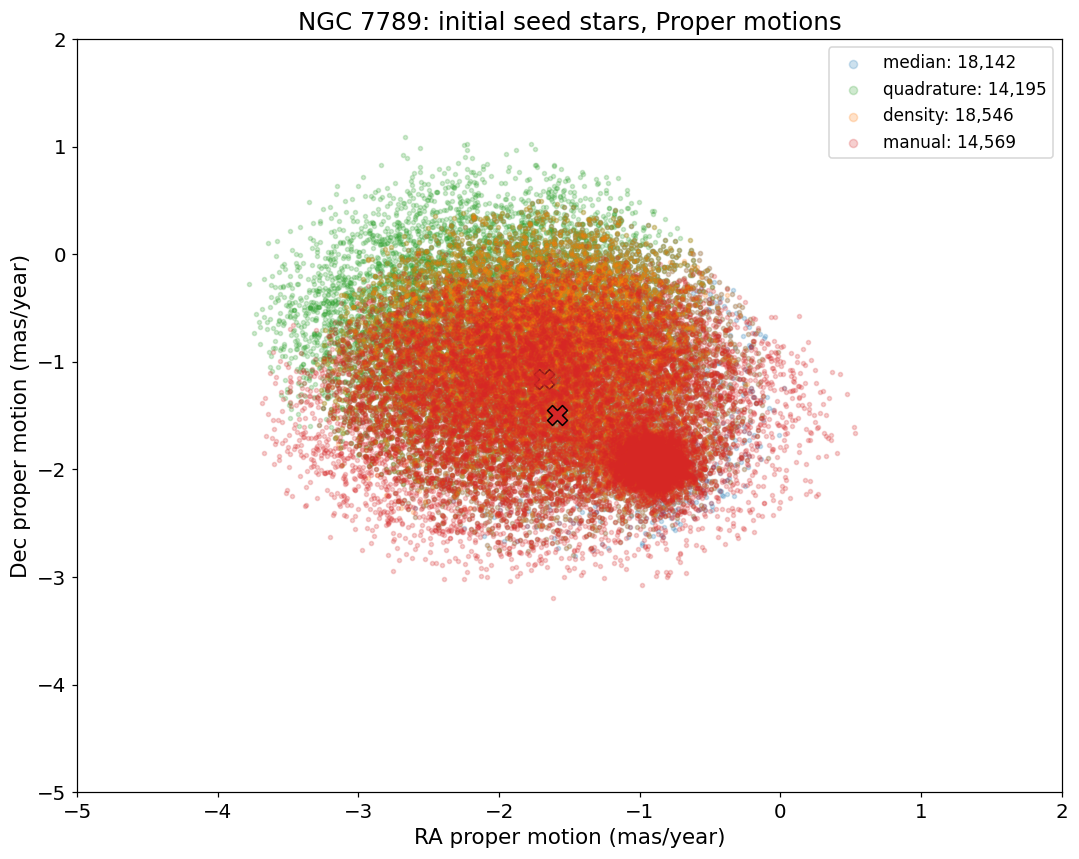

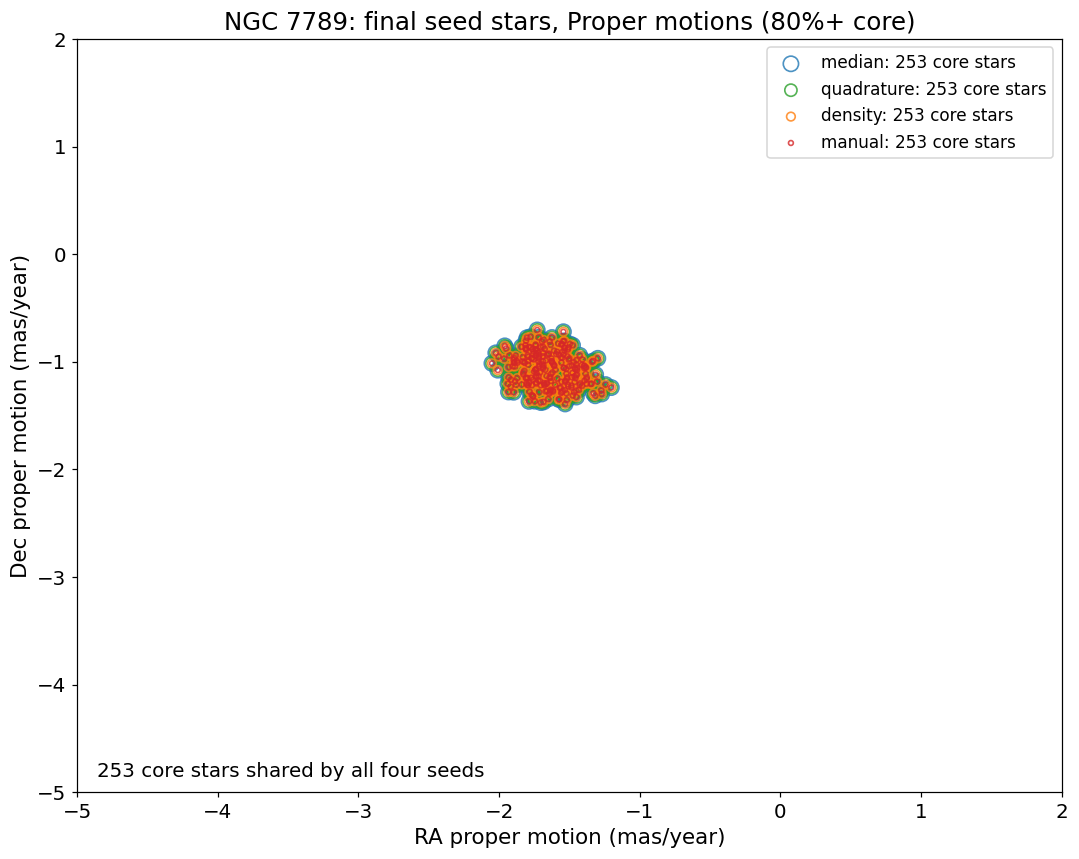

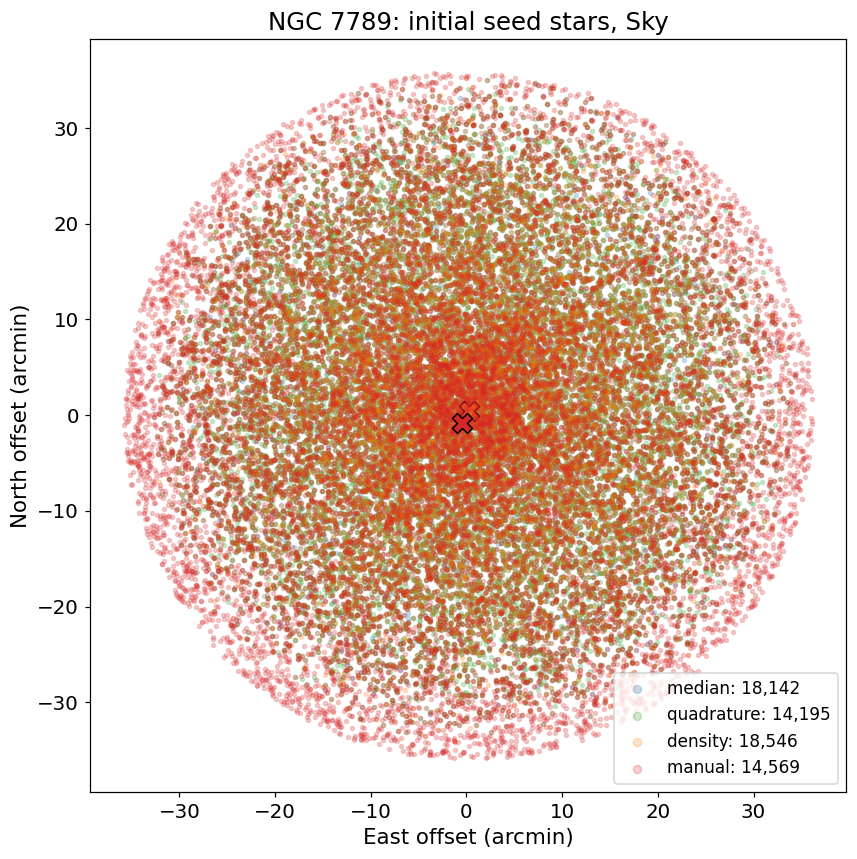

Starting-star locations, first 12 rows per seed. Full table: seed_locations.
median


,source_id,ra,dec,pmra,pmdec,parallax
5,1995033650697110400,358.66395,56.51379,-2.18399,-0.75846,0.17000
7,1995033680754095616,358.63794,56.51057,-2.44047,-1.31019,0.22193
18,1995033715113859200,358.66281,56.52030,-1.13819,-0.69293,0.60142
19,1995033715113870080,358.66099,56.52241,-0.69144,-1.36932,0.00699
22,1995033715113890304,358.67108,56.52643,-2.26874,-1.66976,-0.15256
25,1995033715113907840,358.67399,56.52964,-1.44029,-0.65077,0.15177
43,1995033753776234368,358.71507,56.53202,-0.87628,-1.81586,0.47284
44,1995033753776237312,358.70906,56.52817,-2.36695,-1.81051,0.14423
46,1995033783833444992,358.72631,56.54041,-1.44969,-1.13330,0.20875
49,1995033783835475328,358.72600,56.53647,-1.15425,-2.10033,0.58167


quadrature


,source_id,ra,dec,pmra,pmdec,parallax
5,1995033650697110400,358.66395,56.51379,-2.18399,-0.75846,0.17000
7,1995033680754095616,358.63794,56.51057,-2.44047,-1.31019,0.22193
16,1995033685056760064,358.63322,56.51091,-2.69575,-0.80418,0.44917
18,1995033715113859200,358.66281,56.52030,-1.13819,-0.69293,0.60142
25,1995033715113907840,358.67399,56.52964,-1.44029,-0.65077,0.15177
38,1995033749475725312,358.70050,56.52386,-2.00010,-0.30312,-0.07474
46,1995033783833444992,358.72631,56.54041,-1.44969,-1.13330,0.20875
47,1995033783833452672,358.73838,56.54144,-1.92875,0.26530,0.21512
59,1995033818193151488,358.69837,56.53427,-2.76335,-0.35278,0.37481
61,1995033818193191296,358.70990,56.54222,-2.76844,-0.85860,0.06475


density


,source_id,ra,dec,pmra,pmdec,parallax
5,1995033650697110400,358.66395,56.51379,-2.18399,-0.75846,0.17000
7,1995033680754095616,358.63794,56.51057,-2.44047,-1.31019,0.22193
15,1995033685056759936,358.63804,56.51220,-2.35751,-1.38667,-0.20025
18,1995033715113859200,358.66281,56.52030,-1.13819,-0.69293,0.60142
19,1995033715113870080,358.66099,56.52241,-0.69144,-1.36932,0.00699
22,1995033715113890304,358.67108,56.52643,-2.26874,-1.66976,-0.15256
25,1995033715113907840,358.67399,56.52964,-1.44029,-0.65077,0.15177
26,1995033715113908992,358.66760,56.53014,-1.43418,-1.51184,-0.61254
38,1995033749475725312,358.70050,56.52386,-2.00010,-0.30312,-0.07474
43,1995033753776234368,358.71507,56.53202,-0.87628,-1.81586,0.47284


manual


,source_id,ra,dec,pmra,pmdec,parallax
5,1995033650697110400,358.66395,56.51379,-2.18399,-0.75846,0.17000
7,1995033680754095616,358.63794,56.51057,-2.44047,-1.31019,0.22193
16,1995033685056760064,358.63322,56.51091,-2.69575,-0.80418,0.44917
32,1995033719416486144,358.69104,56.53931,-0.85575,-2.14436,0.48865
37,1995033749473678080,358.71174,56.53477,0.26821,-1.88712,0.43495
43,1995033753776234368,358.71507,56.53202,-0.87628,-1.81586,0.47284
44,1995033753776237312,358.70906,56.52817,-2.36695,-1.81051,0.14423
46,1995033783833444992,358.72631,56.54041,-1.44969,-1.13330,0.20875
49,1995033783835475328,358.72600,56.53647,-1.15425,-2.10033,0.58167
50,1995033783838405248,358.73023,56.54207,-2.36430,-2.35925,0.17155


In [15]:
def final_core_pm_plot(seed_frame, fitted_seeds, palette):
    fig,ax=plt.subplots(figsize=(10,8))
    sizes=[100,64,32,10]
    masks=[]
    for (name,result),size in zip(fitted_seeds.items(),sizes):
        mask=result['core']
        masks.append(mask)
        stars=seed_frame.loc[mask]
        ax.scatter(stars.pmra,stars.pmdec,s=size,facecolors='none',edgecolors=palette[name],
                   linewidths=1.1,alpha=.8,label=f'{name}: {len(stars):,} core stars')
    shared=int(np.logical_and.reduce(masks).sum())
    ax.set(title='NGC 7789: final seed stars, Proper motions (80%+ core)',
           xlabel='RA proper motion (mas/year)',ylabel='Dec proper motion (mas/year)',
           xlim=(-5,2),ylim=(-5,2))
    ax.text(.02,.02,f'{shared:,} core stars shared by all four seeds',transform=ax.transAxes)
    ax.legend();fig.tight_layout()
    return fig

seed_colors={'median':'tab:blue','quadrature':'tab:green','density':'tab:orange','manual':'tab:red'}
views=[('bp_rp','phot_g_mean_mag','BP - RP color','G magnitude','CMD'),
       ('pmra','pmdec','RA proper motion (mas/year)','Dec proper motion (mas/year)','Proper motions'),
       ('sky_x','sky_y','East offset (arcmin)','North offset (arcmin)','Sky')]
seed_locations=seed_df[['source_id','ra','dec','pmra','pmdec','parallax','bp_rp','phot_g_mean_mag']].copy()
seed_locations['sky_x']=60*xsky; seed_locations['sky_y']=60*ysky
for name,start in starts.items():seed_locations[f'initial_{name}']=start['prob']>=.5
for xcol,ycol,xlabel,ylabel,title in views:
    fig,ax=plt.subplots(figsize=(10,8))
    for name,start in starts.items():
        stars=seed_locations.loc[start['prob']>=.5]
        ax.scatter(stars[xcol],stars[ycol],s=7,color=seed_colors[name],alpha=.22,rasterized=True,label=f'{name}: {len(stars):,}')
        loc=start['center']*raw_scale+means
        if title=='Proper motions':ax.scatter(loc[0],loc[1],marker='X',s=170,color=seed_colors[name],edgecolor='black')
        if title=='Sky':ax.scatter(loc[3]*60,loc[4]*60,marker='X',s=170,color=seed_colors[name],edgecolor='black')
    if title=='CMD':
        closed=np.vstack([vertices,vertices[0]])
        ax.plot(closed[:,0],closed[:,1],color='tab:red',linewidth=2)
        ax.set(xlim=(.2,2.2),ylim=(18.5,10))
    if title=='Proper motions':ax.set(xlim=(-5,2),ylim=(-5,2))
    if title=='Sky':ax.set_aspect('equal',adjustable='box')
    ax.set(title=f'NGC 7789: initial seed stars, {title}',xlabel=xlabel,ylabel=ylabel)
    ax.legend(markerscale=2);fig.tight_layout();plt.show()
    if title=='Proper motions':
        final_core_pm_plot(seed_df,seed_results,seed_colors)
        plt.show()
print('Starting-star locations, first 12 rows per seed. Full table: seed_locations.')
for name in starts:
    print(name)
    display(seed_locations.loc[seed_locations[f'initial_{name}'],['source_id','ra','dec','pmra','pmdec','parallax']].head(12).round(5))

Compare the final core stars on the diagrams

Show a full-size core CMD for each seed. Then plot the stars shared by every seed in black and any extra stars in the seed's color. This makes small differences visible in proper motion and sky position, rather than covering identical groups with four layers of points.

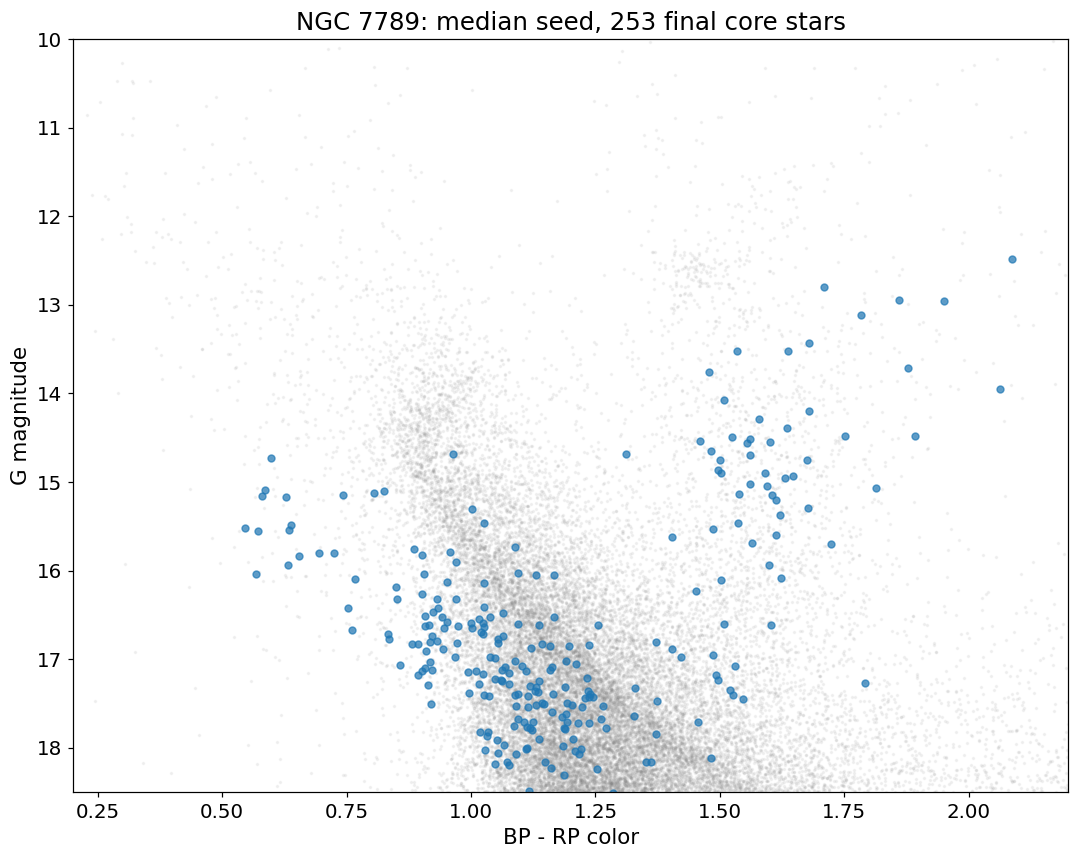

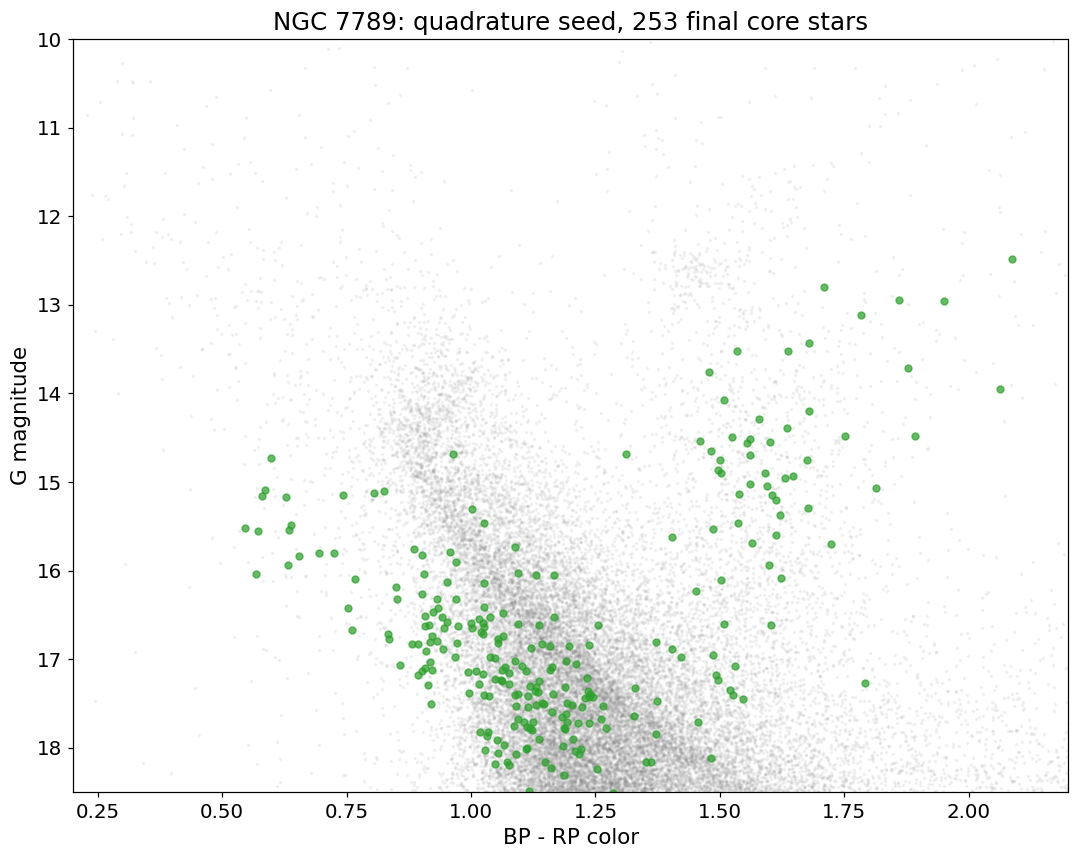

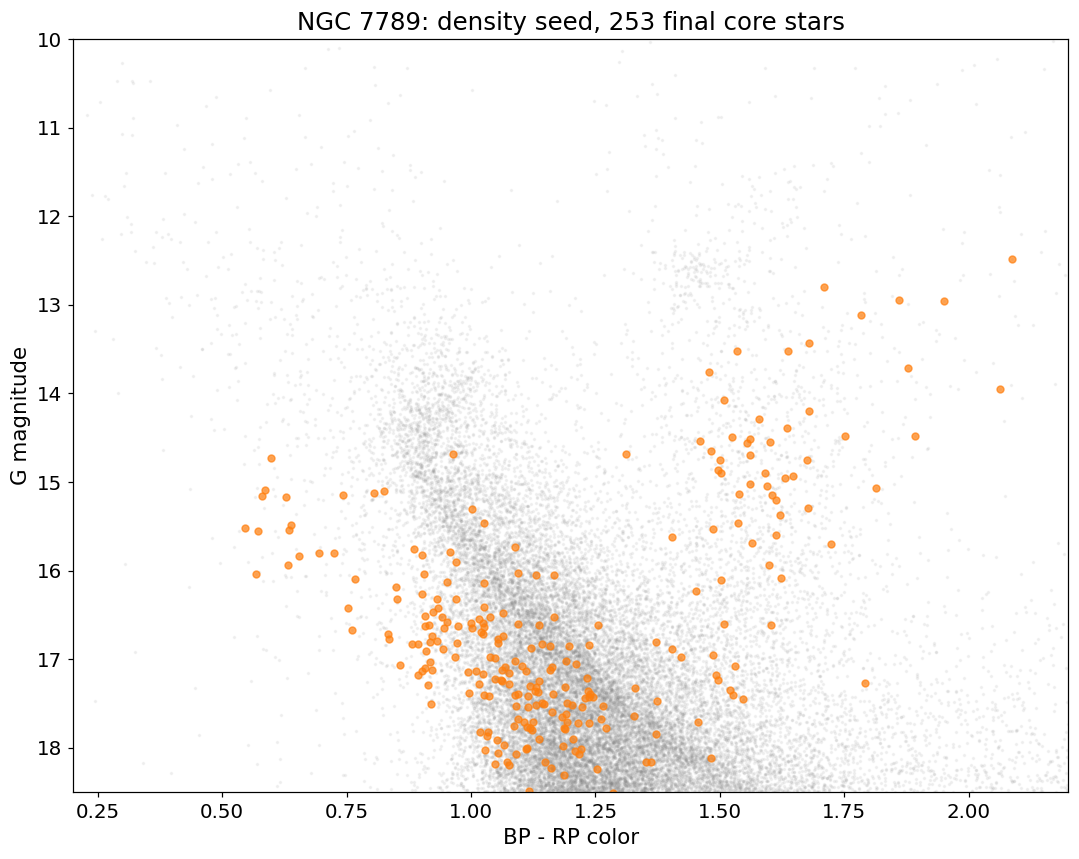

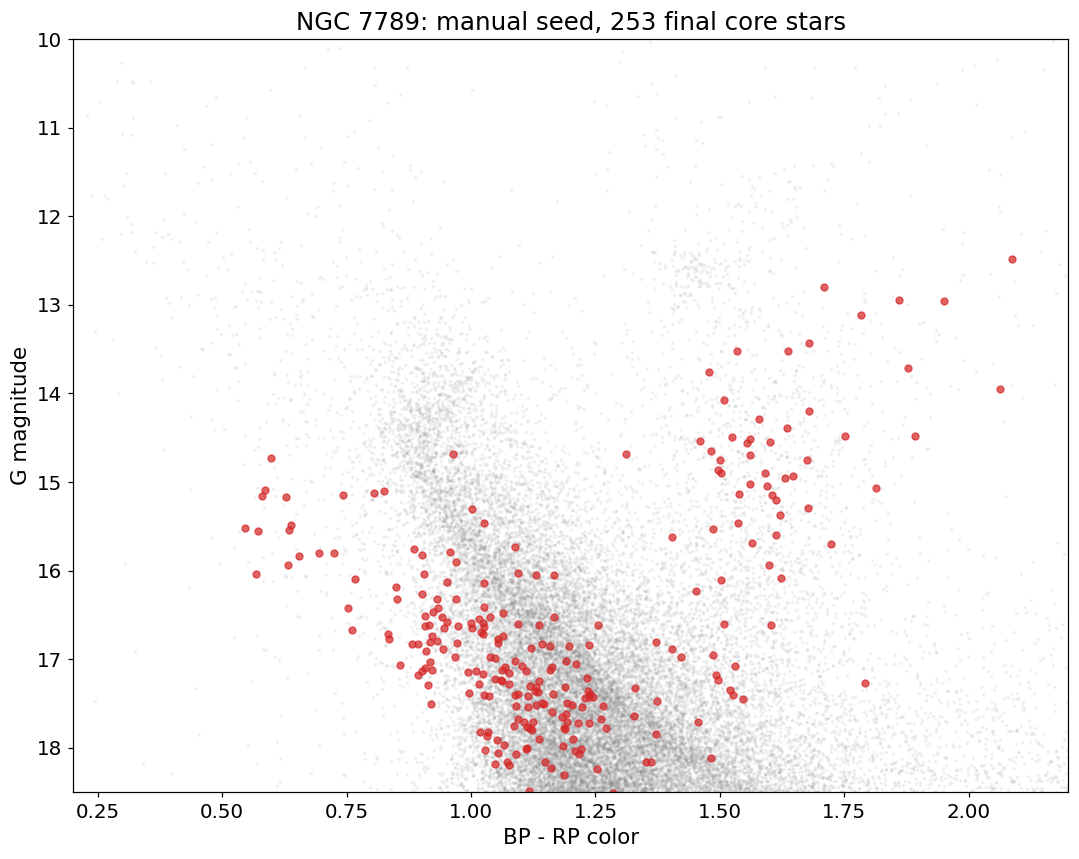

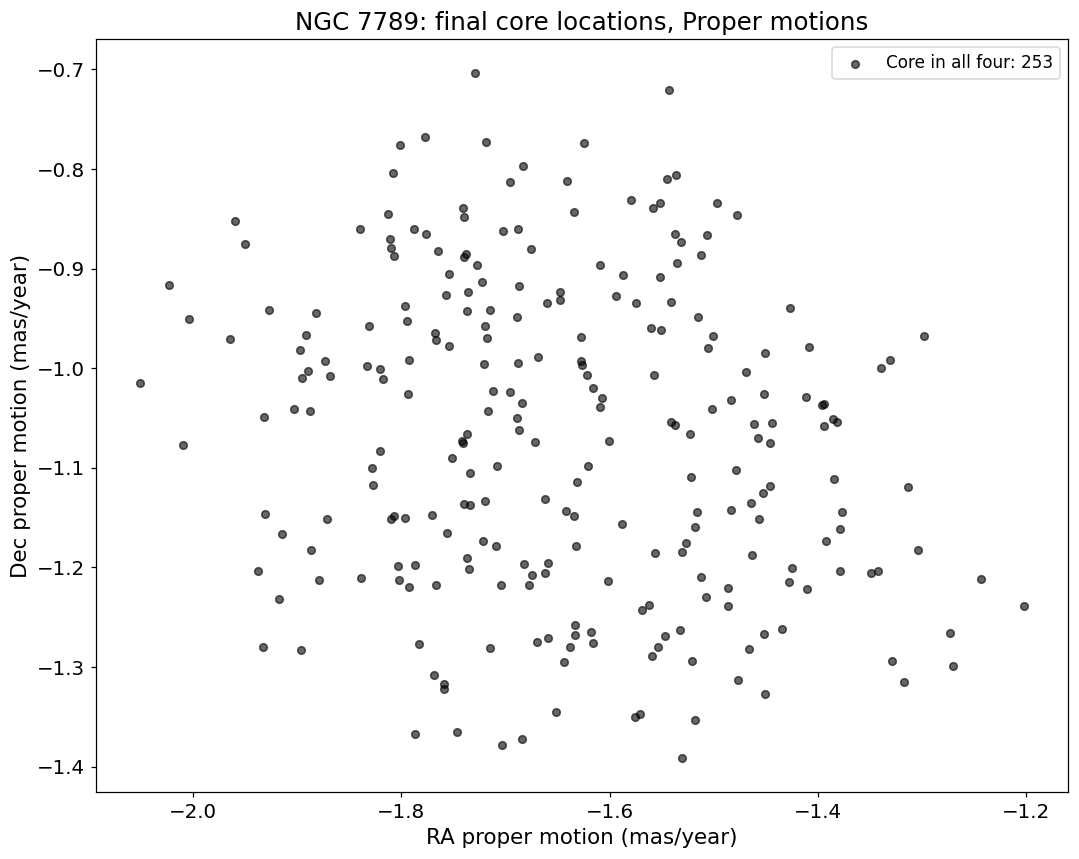

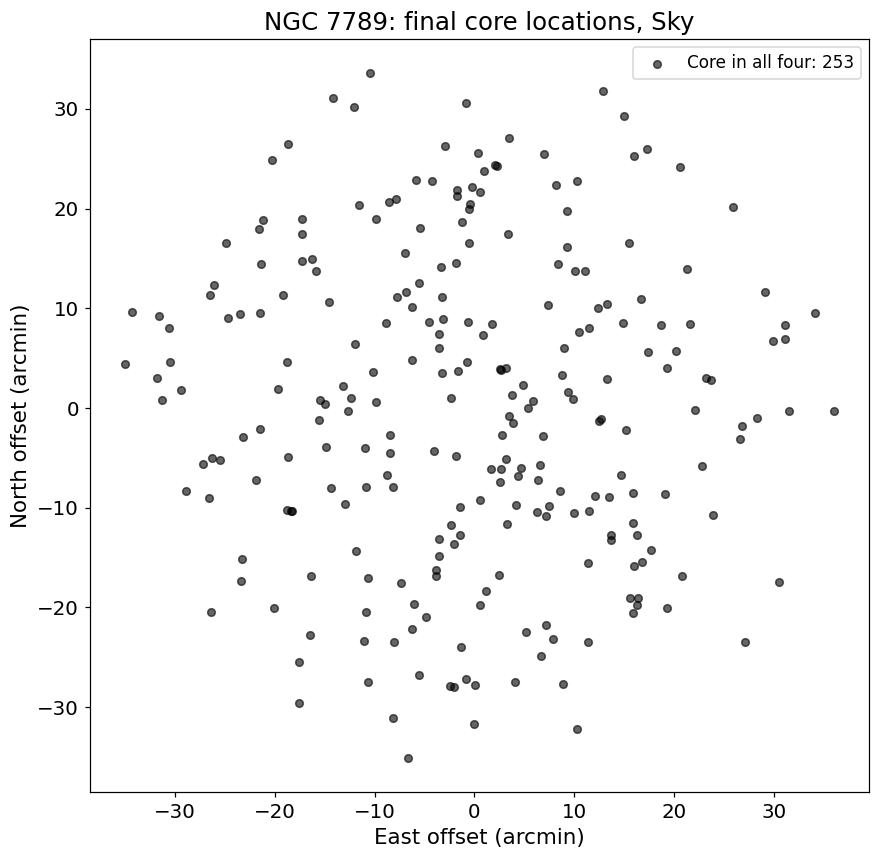

Final core-star locations, first 20 rows. Full table: core_locations.


,source_id,ra,dec,pmra,pmdec,parallax,...,core_quadrature,P_quadrature,core_density,P_density,core_manual,P_manual
473,1995035020782198912,358.67981,56.58800,-1.39437,-1.05819,0.29013,...,True,0.80785,True,0.80795,True,0.80787
914,1995036158957854848,358.89253,56.64319,-2.05072,-1.01429,0.22208,...,True,0.80376,True,0.80375,True,0.80376
1094,1995036635692127104,358.77671,56.62780,-1.62733,-0.99257,0.20563,...,True,0.80501,True,0.80507,True,0.80502
1358,1995037322882402048,358.95847,56.70364,-1.58776,-1.15647,0.23706,...,True,0.80187,True,0.80197,True,0.80189
1424,1995037464627914624,358.53435,56.55845,-1.64171,-1.14357,0.20951,...,True,0.81431,True,0.81436,True,0.81432
1853,1995038632858946816,358.51857,56.61586,-1.91722,-1.23136,0.20378,...,True,0.80468,True,0.80469,True,0.80469
1860,1995038662916662016,358.54478,56.62518,-1.67756,-1.21736,0.24492,...,True,0.80713,True,0.80719,True,0.80714
1885,1995038701578430592,358.56954,56.62190,-1.44594,-1.07514,0.19682,...,True,0.80633,True,0.80641,True,0.80634
2069,1995039182614740224,358.63844,56.66137,-1.60032,-1.07303,0.20888,...,True,0.80973,True,0.80979,True,0.80974
2120,1995039315753336576,358.68973,56.67436,-1.66974,-1.27439,0.23571,...,True,0.80008,True,0.80015,True,0.80010


In [17]:
core_masks={name:r['core'] for name,r in seed_results.items()}
common_core=np.logical_and.reduce(list(core_masks.values()))
for name,result in seed_results.items():
    fig,ax=plt.subplots(figsize=(10,8))
    ax.scatter(seed_df.bp_rp,seed_df.phot_g_mean_mag,s=2,color='gray',alpha=.08,rasterized=True)
    stars=seed_df.loc[result['core']]
    ax.scatter(stars.bp_rp,stars.phot_g_mean_mag,s=20,color=seed_colors[name],alpha=.7,rasterized=True)
    ax.set(title=f'NGC 7789: {name} seed, {len(stars):,} final core stars',xlabel='BP - RP color',ylabel='G magnitude',xlim=(.2,2.2),ylim=(18.5,10))
    fig.tight_layout();plt.show()
for xcol,ycol,xlabel,ylabel,title in views[1:]:
    fig,ax=plt.subplots(figsize=(10,8))
    shared=seed_locations.loc[common_core]
    ax.scatter(shared[xcol],shared[ycol],s=25,color='black',alpha=.6,label=f'Core in all four: {len(shared)}')
    for name,mask in core_masks.items():
        extra=seed_locations.loc[mask&~common_core]
        if len(extra):ax.scatter(extra[xcol],extra[ycol],s=45,color=seed_colors[name],label=f'{name}, outside shared set: {len(extra)}')
    ax.set(title=f'NGC 7789: final core locations, {title}',xlabel=xlabel,ylabel=ylabel)
    if title=='Sky':ax.set_aspect('equal',adjustable='box')
    ax.legend();fig.tight_layout();plt.show()
core_locations=seed_locations[['source_id','ra','dec','pmra','pmdec','parallax','bp_rp','phot_g_mean_mag']].copy()
for name,r in seed_results.items():
    core_locations[f'core_{name}']=r['core']
    core_locations[f'P_{name}']=r['final']
core_locations=core_locations.loc[np.logical_or.reduce(list(core_masks.values()))]
print('Final core-star locations, first 20 rows. Full table: core_locations.')
display(core_locations.head(20).round(5))

Measure core overlap and movement during fitting

The first table counts shared core stars. The percentage table uses intersection divided by union, so 100% means identical core membership. The final table counts stars found in only one seed's core group. The center paths show whether different starting locations move toward the same fitted population.

Shared final core stars:


,median,quadrature,density,manual
median,253,253,253,253
quadrature,253,253,253,253
density,253,253,253,253
manual,253,253,253,253


Shared core as percentage of the union:


,median,quadrature,density,manual
median,100.0,100.0,100.0,100.0
quadrature,100.0,100.0,100.0,100.0
density,100.0,100.0,100.0,100.0
manual,100.0,100.0,100.0,100.0


,core stars unique to this seed
seed,
median,0
quadrature,0
density,0
manual,0


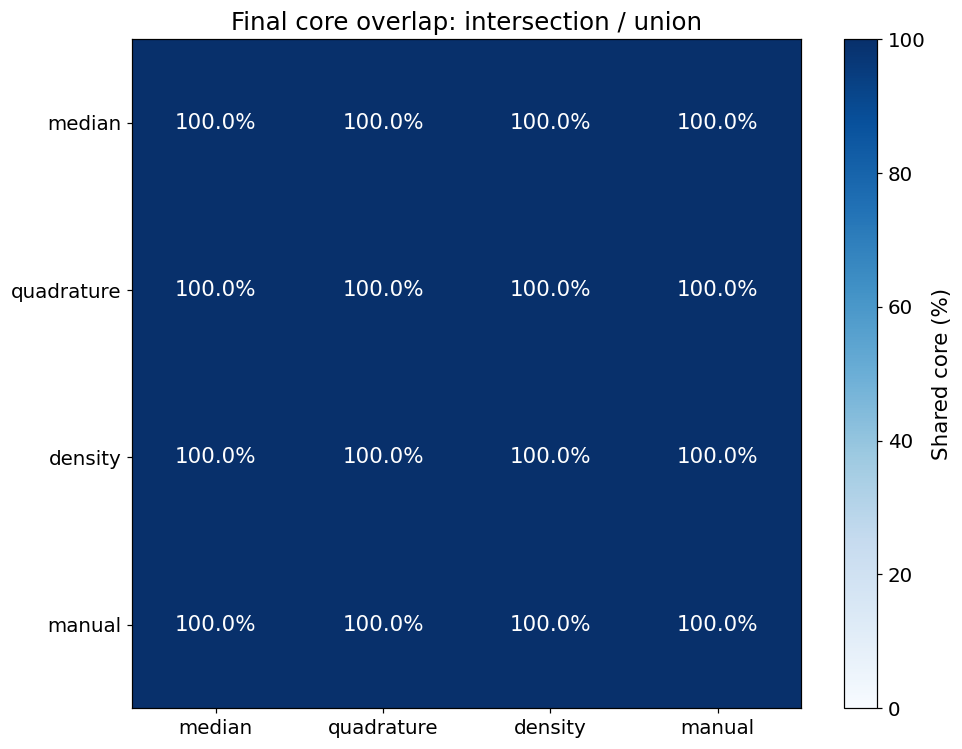

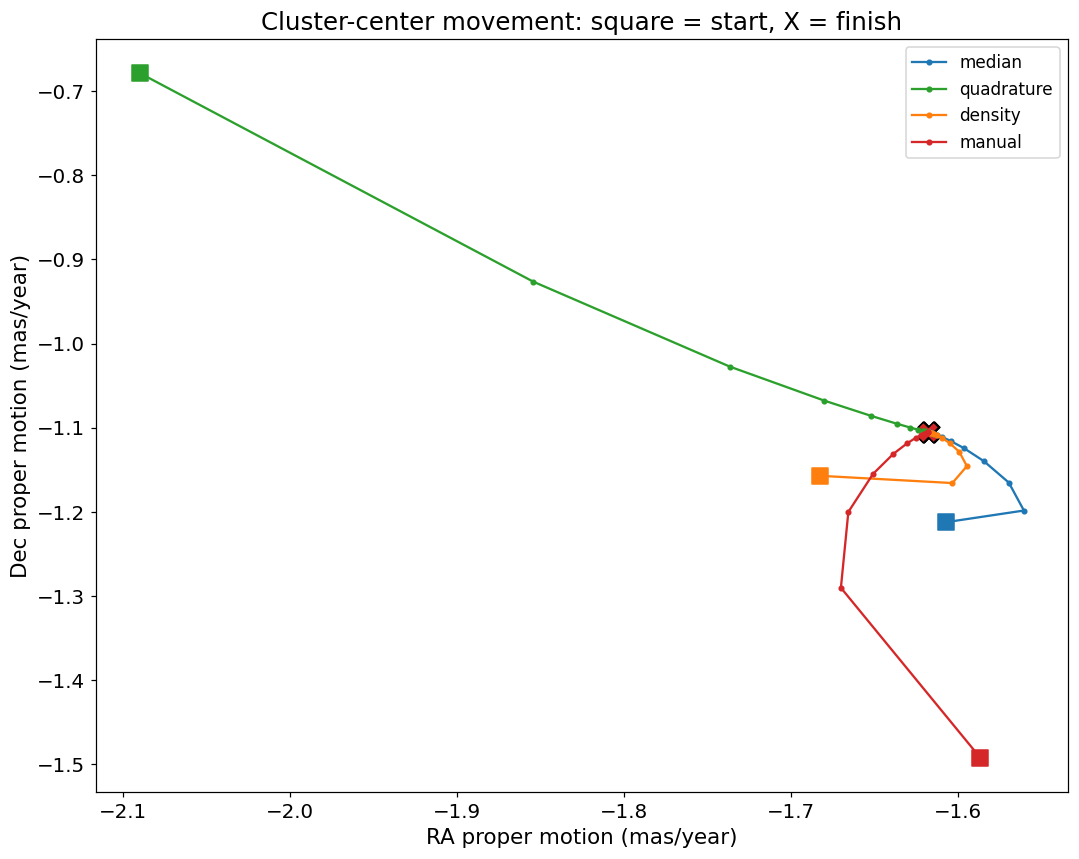

The lowest pairwise final-core overlap is 100.00%.
These different starts lead to effectively the same final core population. Changing this seed alone does not resolve the result.
The manual CMD contains 20,190 stars (27.42% of the input), but every fit retains the same max cluster fraction of 0.080.
The fraction limit is part of the existing model and was held fixed in this comparison.


In [18]:
names=list(seed_results)
shared_counts=pd.DataFrame(index=names,columns=names,dtype=int)
shared_percent=pd.DataFrame(index=names,columns=names,dtype=float)
for left in names:
    for right in names:
        shared=int((core_masks[left]&core_masks[right]).sum())
        union=int((core_masks[left]|core_masks[right]).sum())
        shared_counts.loc[left,right]=shared
        shared_percent.loc[left,right]=100*shared/union if union else np.nan
print('Shared final core stars:');display(shared_counts.astype(int))
print('Shared core as percentage of the union:');display(shared_percent.round(2))
unique_rows=[]
for name in names:
    others=np.logical_or.reduce([core_masks[other] for other in names if other!=name])
    unique_rows.append({'seed':name,'core stars unique to this seed':int((core_masks[name]&~others).sum())})
display(pd.DataFrame(unique_rows).set_index('seed'))
fig,ax=plt.subplots(figsize=(9,7))
image=ax.imshow(shared_percent.to_numpy(float),vmin=0,vmax=100,cmap='Blues')
ax.set_xticks(range(4),names);ax.set_yticks(range(4),names)
for i in range(4):
    for j in range(4):
        value=shared_percent.iloc[i,j]
        ax.text(j,i,f'{value:.1f}%',ha='center',va='center',color='white' if value>60 else 'black',fontsize=14)
ax.set_title('Final core overlap: intersection / union')
fig.colorbar(image,ax=ax,label='Shared core (%)');fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(10,8))
for name,result in seed_results.items():
    path=result['trace']
    ax.plot(path[:,0],path[:,1],color=seed_colors[name],marker='.',label=name)
    ax.scatter(path[0,0],path[0,1],s=110,marker='s',color=seed_colors[name])
    ax.scatter(path[-1,0],path[-1,1],s=180,marker='X',color=seed_colors[name],edgecolor='black')
ax.set(title='Cluster-center movement: square = start, X = finish',xlabel='RA proper motion (mas/year)',ylabel='Dec proper motion (mas/year)')
ax.legend();fig.tight_layout();plt.show()
minimum_overlap=min(shared_percent.loc[a,c] for i,a in enumerate(names) for c in names[i+1:])
print(f'The lowest pairwise final-core overlap is {minimum_overlap:.2f}%.')
if minimum_overlap>=99:
    print('These different starts lead to effectively the same final core population. Changing this seed alone does not resolve the result.')
else:
    print('The starting seed changes some final core assignments. Inspect the differing stars in core_locations.')
print(f'The manual CMD contains {manual_mask.sum():,} stars ({100*manual_mask.mean():.2f}% of the input), but every fit retains the same max cluster fraction of {max_pi:.3f}.')
print('The fraction limit is part of the existing model and was held fixed in this comparison.')